# Cell type annotation transfer
This notebook transfers the consensus cell types of the TMA dataset to the new non-TMA dataset. The consensus labels come from `lineage/annotation_consensus.ipynb` and are stored in `adata_consensus_cell_types.h5ad`. The new cell table comes from `SegmentAndExtract.ipynb` and `FilterAndAggregate.ipynb`.

## Approach
The original annotation combined a hierarchical gating, a FlowSOM clustering annotated by hand, and Scyan. The hand annotation of the FlowSOM clusters is not available and the two panels differ, so this notebook trains an XGBoost classifier on the TMA cells and their consensus labels, then applies it to the new cells. The classifier uses the 13 lineage channels that both panels measure. Two of them are measured with different antibodies:
* `Calprotectin` in the new panel stands in for `MPO` in the reference, for neutrophils.
* `PanCK_EpCAM` in the new panel stands in for `PanCK` in the reference.

The classifier sees the new values of these two channels in the place of the reference ones.

Two reference channels are missing from the new panel:
* Without `HLADRa`, APCs cannot be told apart and are merged into `Other_immune_cell`.
* Without `CD7`, NK cells do not form a separate population. They stay a class, but the classifier finds few of them. The `annotation_grouped` column merges NK cells and CD8 T cells into `Cytotoxic_lymphocyte`, as `multicellular/PrepareMuData.ipynb` does.

Several lineage channels of the new images have a higher background than the reference, for example `FoxP3`, `CD4`, `CD3e` and `CD163`. Before annotation, the notebook subtracts the 25th percentile of the raw intensities from each lineage channel. The channel distributions are not matched to the reference beyond that, see the section on background subtraction. The exported `cell_table_transformed.csv` keeps the original transformation without this subtraction.

## Evidence that the transferred populations are coherent
The new cells have no labels, so no accuracy can be measured on them. The notebook builds the case in steps:
1. On reference FOVs held out from training, the classifier recovers the consensus labels. This tests the classifier, not the transfer.
2. In the new dataset, each transferred population has the lineage marker profile of its reference counterpart, and agrees with the hierarchical gating of `Annotation_gating_Hamburg.ipynb` almost as often as the reference does. The classifier uses these channels, so this shows consistency rather than independent confirmation.
3. Channels that the classifier never sees separate the populations as expected, for example `CD36` for macrophages and monocytes, and `Vimentin`, which ranks the cell types as in the reference. Two of the five tested channels, `COL1A1` and `HNF4a`, separate nothing and give no support either way.
4. Cell positions, which the classifier never sees either, show that each transferred population sits next to cells of its own type far more often than chance, as in the reference.
5. A classifier without `MPO` and `PanCK` finds `Calprotectin`-high neutrophils and `PanCK_EpCAM`-high cancer cells, so the two replacement channels mark the expected cells.

Setting low-confidence predictions to `Unclear` improves these checks only slightly, removes many immune cells and lowers the F1 score of every type on the reference, so no cutoff is applied. The exported `annotation_confidence` column allows one later.

The coarse classes of `PrepareMuData.ipynb` come from grouping the fine predictions. A classifier trained directly on the coarse classes did no better on any class.

Plots follow `lineage/CellTypeViz.ipynb`: the same cell type and marker order, median heatmaps with the reversed plasma palette, and flipped violin plots with the median as a point. Agreement matrices use the viridis palette of the confusion matrix in `lineage/annotation_consensus.ipynb`, and correlations go from orange to blue. Most plots compare the reference with the new dataset, so their colors stand for datasets: blue for the reference and orange for the new dataset. The exported AnnData stores the cell type colors of `CellTypeViz.ipynb` for later plots. Figures are saved to `figures/sampling/annotation_transfer/`.

## Imports

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import anndata as ad
from plotnine import *
from scanpy.plotting.palettes import default_20
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

sys.path.insert(0, "../.utils")
from plot_labels import display_name, display_types

In [ ]:
seed = 10 # As in annotation_consensus.ipynb
data_dir = "../../data/"
figure_dir = "../../figures/sampling/annotation_transfer/"
os.makedirs(figure_dir, exist_ok=True)
background_quantile = 0.25

## Prepare data
### Panel correspondence

In [12]:
# New channels standing in for reference channels
new_to_ref = {"Calprotectin": "MPO", "PanCK_EpCAM": "PanCK"}
ref_to_new = {v: k for k, v in new_to_ref.items()}

# Without HLADRa, APCs cannot be resolved
unresolvable_types = {"APC": "Other_immune_cell"}

# Coarser classes of multicellular/PrepareMuData.ipynb
type_groups = dict(
    Other_immune_cell = ["APC", "B_cell", "Neutrophil", "Other_immune_cell"],
    Fibroblast = ["CAF"],
    Macrophage = ["CD163_Macrophage", "CD68_Macrophage"],
    CD4_lymphocyte = ["CD4_Tcell", "T_reg_cell"],
    Epithelial_cell = ["Cancer_cell"],
    Endothelial_cell = ["Endothelial_cell"],
    Monocyte = ["Monocyte"],
    Cytotoxic_lymphocyte = ["NK_cell", "CD8_Tcell"],
)
type_to_group = {t: group for group, types in type_groups.items() for t in types}

### Load reference (TMA) annotation

In [13]:
ref = ad.read_h5ad(data_dir + "adata_consensus_cell_types.h5ad")
ref_X = pd.DataFrame(ref.X, columns=ref.var_names, index=ref.obs_names)
ref_labels = ref.obs["annotation_consensus"].astype(str).replace(unresolvable_types)
ref_labels.value_counts().rename(index=display_name)

annotation_consensus
Epithelial cell      262411
Unclear               90917
Fibroblast            75961
Monocyte              29922
Endothelial cell      29646
Neutrophil            19169
Other immune cell     17716
CD4 Tcell             15340
CD68 Macrophage       10775
CD163 Macrophage      10747
CD8 Tcell              6824
NK cell                3973
B cell                 3684
T reg cell             1926
Name: count, dtype: int64

### Plot settings

In [14]:
# Cell type colors of lineage/CellTypeViz.ipynb, scanpy default palette in the category order of the reference.
# Stored in the exported AnnData.
type_colors = dict(zip(ref.obs["annotation_consensus"].cat.categories, default_20))

# Cell type and marker order of lineage/CellTypeViz.ipynb, without APCs and the channels missing in the new panel
cell_types_ordered = [
    "T_reg_cell", "CD4_Tcell", "CD8_Tcell", "NK_cell",
    "B_cell", "CD68_Macrophage", "CD163_Macrophage",
    "Other_immune_cell", "Monocyte", "Neutrophil",
    "Cancer_cell", "Endothelial_cell", "CAF", "Unclear",
]
markers_ordered = [
    "SMA", "CD31", "PanCK", "MPO",
    "CD14", "CD163", "CD68", "CD20",
    "CD8", "CD4", "FoxP3", "CD3e", "CD45",
]
coarse_ordered = [
    "CD4_lymphocyte", "Cytotoxic_lymphocyte", "Macrophage", "Monocyte", "Other_immune_cell",
    "Epithelial_cell", "Endothelial_cell", "Fibroblast", "Unclear",
]

# Channel names: a panel showing one dataset uses the channels of that dataset,
# a panel showing both datasets says which channel each dataset contributes
new_channel = lambda m: ref_to_new.get(m, m)
both_names = {m: f"{m} in reference,\n{new_channel(m)} in new" if m in ref_to_new else m for m in markers_ordered}

# Dataset colors. Purple and green stand for cancer and healthy tissue in this project, so datasets use
# blue for the reference and shades of orange for the new dataset.
dataset_colors = {
    "Reference (TMA)": "#80b1d3",
    "New": "#fdb462",
    "New, tumor core": "#d95f0e",
    "New, invasive margin": "#fee391",
    "New, shuffled labels": "#bdbdbd",
}

# Reversed plasma palette of lineage/CellTypeViz.ipynb
plasma_reversed = ["#EFF822", "#CC4977", "#0F0782"]

def percent_labels(breaks):
    return [f"{b:.0%}" for b in breaks]

def tile_labels(df, value="Fraction"):
    """Percent labels for viridis heatmap tiles, white on dark tiles and black on light tiles"""
    df["label"] = [f"{v:.0%}" if v >= 0.005 else "" for v in df[value]]
    df["text_color"] = np.where(df[value] < 0.6, "white", "black")
    return df

# Correlations, orange to blue as in validation/Heiser.ipynb
def scale_fill_correlation():
    return scale_fill_gradient2(low="#FC8D62", mid="white", high="#6291FC", midpoint=0, limits=(-1, 1))

### Load and transform new dataset
The transformation is the one of `preprocessing/TransformMarkerData.ipynb`. It scales the 99.9th percentile of each channel to 10, applies an arcsinh transform, then scales the 99.9th percentile to 1. The percentiles come from the new dataset.

In [15]:
raw_cells = pd.read_csv(data_dir + "sampling/cell_table.csv", index_col=0)

# Background channel dropped, nuclear and membrane channels kept but not transformed
raw_cells = raw_cells.drop(columns=["Au"])
not_transformed = ["nuclei", "membrane", "centroid-0", "centroid-1", "eccentricity", "perimeter",
                   "convex_area", "area", "axis_major_length", "axis_minor_length", "label", "fov"]
channels = [c for c in raw_cells.columns if c not in not_transformed]

def transform_channels(X, desired_percentile_value=10):
    """Transformation of preprocessing/TransformMarkerData.ipynb"""
    multiplying_factors = desired_percentile_value / X.quantile(.999)
    assert np.isfinite(multiplying_factors).all()
    return np.arcsinh(X * multiplying_factors) / np.arcsinh(desired_percentile_value)

cells = raw_cells.copy()
cells[channels] = transform_channels(raw_cells[channels])
cells[channels].describe()

,CD4,CD20,FoxP3,CD14,GLUT1,COL1A1,CD68,CS,CytC,LDH,...,PanCK_EpCAM,SMA,HNF4a,PDL1,CD8,CD45,AKT,CD36,CD163,Vimentin
count,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,...,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000,683041.000000
mean,0.226230,0.055141,0.285285,0.167463,0.228710,0.168089,0.106993,0.315281,0.235188,0.376973,...,0.177220,0.089156,0.444548,0.294792,0.077718,0.184913,0.519937,0.177945,0.132793,0.138684
std,0.170532,0.099833,0.131684,0.172248,0.153459,0.166514,0.139443,0.182382,0.193513,0.190441,...,0.197794,0.146405,0.175983,0.138675,0.124446,0.213787,0.190467,0.146059,0.131541,0.160509
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000701,0.000000,0.000000,0.000000
25%,0.106832,0.017370,0.193541,0.051730,0.118847,0.047931,0.032473,0.174897,0.082110,0.231320,...,0.031442,0.003965,0.317920,0.200701,0.027702,0.025192,0.392917,0.078308,0.060402,0.031307
50%,0.181415,0.030724,0.274138,0.096723,0.193687,0.103598,0.056293,0.286128,0.177033,0.369086,...,0.080611,0.024185,0.445169,0.279735,0.043177,0.072445,0.537584,0.134228,0.092055,0.068355
75%,0.294576,0.051138,0.360474,0.223908,0.299664,0.237885,0.110067,0.427079,0.346139,0.508443,...,0.273726,0.105812,0.565458,0.368601,0.068119,0.302751,0.657985,0.230670,0.147052,0.191779
max,1.998260,1.432681,1.399248,1.358322,1.630567,1.393851,1.461819,1.378003,1.346477,1.676911,...,1.373217,1.440081,1.601430,1.703965,1.351480,1.267178,1.218929,1.595538,1.525706,1.525926


In [16]:
cells.to_csv(data_dir + "sampling/cell_table_transformed.csv")

### Background subtraction of lineage channels
The classifier learns thresholds on the reference values, so the new values should be on a comparable scale. The notebook does two things to each of the 13 lineage channels before applying the classifier:
1. It subtracts the 25th percentile of the raw intensities and sets negative values to 0. In the reference, most cells sit near 0 for each lineage channel, while the new images have a raised floor.
2. It applies the transformation above, with percentiles from the new dataset, so the 99.9th percentile becomes 1 in both datasets.

The distributions between these two ends are not matched to the reference. The table and the density plot below show where they still differ, for example `FoxP3`.

Full quantile matching, which would give each new channel the reference distribution, was tested outside this notebook and not kept. It imposes the reference marker distributions, and with them the reference cell type mix. Half of the new FOVs come from the invasive margin and contain more immune cells than the TMA cores, so quantile matching pushes some immune cells to the CD45 levels of non-immune reference cells. In that test the fraction of cancer cells rose from 34% to 41%, close to the 45% of the reference, partly as an effect of the matching itself.

Only the annotation uses the background-subtracted values.

In [17]:
# Lineage channels shared by both panels, named as in the reference
shared_channels = [c for c in ref.var_names if c in cells.rename(columns=new_to_ref).columns]
print("Missing in new panel:", [c for c in ref.var_names if c not in shared_channels])
ref_X = ref_X[shared_channels]

raw_lineage = raw_cells[[new_channel(c) for c in shared_channels]]
background = raw_lineage.quantile(background_quantile)
new_X = transform_channels((raw_lineage - background).clip(lower=0)).rename(columns=new_to_ref)
new_panel_X = new_X.rename(columns=ref_to_new)

Missing in new panel: ['CD7', 'HLADRa']


In [18]:
# Remaining differences: quantiles of each channel in the reference and in the new dataset after background subtraction
quantiles = [0.25, 0.5, 0.75, 0.99]
quantile_table = pd.concat({"Reference": ref_X.quantile(quantiles).T, "New": new_X.quantile(quantiles).T}, axis=1).loc[markers_ordered]
quantile_table.insert(0, ("New", "channel"), [new_channel(m) for m in markers_ordered])
quantile_table.index.name = "Reference channel"
quantile_table.round(3)

New Reference                       New         \
                        channel      0.25    0.5   0.75   0.99 0.25    0.5   
Reference channel                                                            
SMA                         SMA     0.000  0.000  0.069  0.770  0.0  0.020   
CD31                       CD31     0.009  0.027  0.070  0.682  0.0  0.027   
PanCK               PanCK_EpCAM     0.027  0.098  0.246  0.766  0.0  0.050   
MPO                Calprotectin     0.001  0.003  0.006  0.577  0.0  0.007   
CD14                       CD14     0.031  0.059  0.136  0.736  0.0  0.047   
CD163                     CD163     0.001  0.006  0.023  0.605  0.0  0.033   
CD68                       CD68     0.004  0.013  0.041  0.627  0.0  0.024   
CD20                       CD20     0.001  0.004  0.013  0.395  0.0  0.013   
CD8                         CD8     0.000  0.003  0.015  0.546  0.0  0.016   
CD4                         CD4     0.016  0.055  0.140  0.732  0.0  0.084   
FoxP3                     FoxP3     0.007  0.029  0.078  0.583  0.0  0.106   
CD3e                       CD3e     0.007  0.018  0.040  0.729  0.0  0.046   
CD45                       CD45     0.015  0.029  0.128  0.757  0.0  0.048   

                                 
                    0.75   0.99  
Reference channel                
SMA                0.102  0.674  
CD31               0.085  0.713  
PanCK              0.252  0.795  
MPO                0.026  0.777  
CD14               0.183  0.767  
CD163              0.092  0.696  
CD68               0.080  0.698  
CD20               0.034  0.586  
CD8                0.041  0.712  
CD4                0.218  0.789  
FoxP3              0.227  0.658  
CD3e               0.133  0.777  
CD45               0.287  0.820

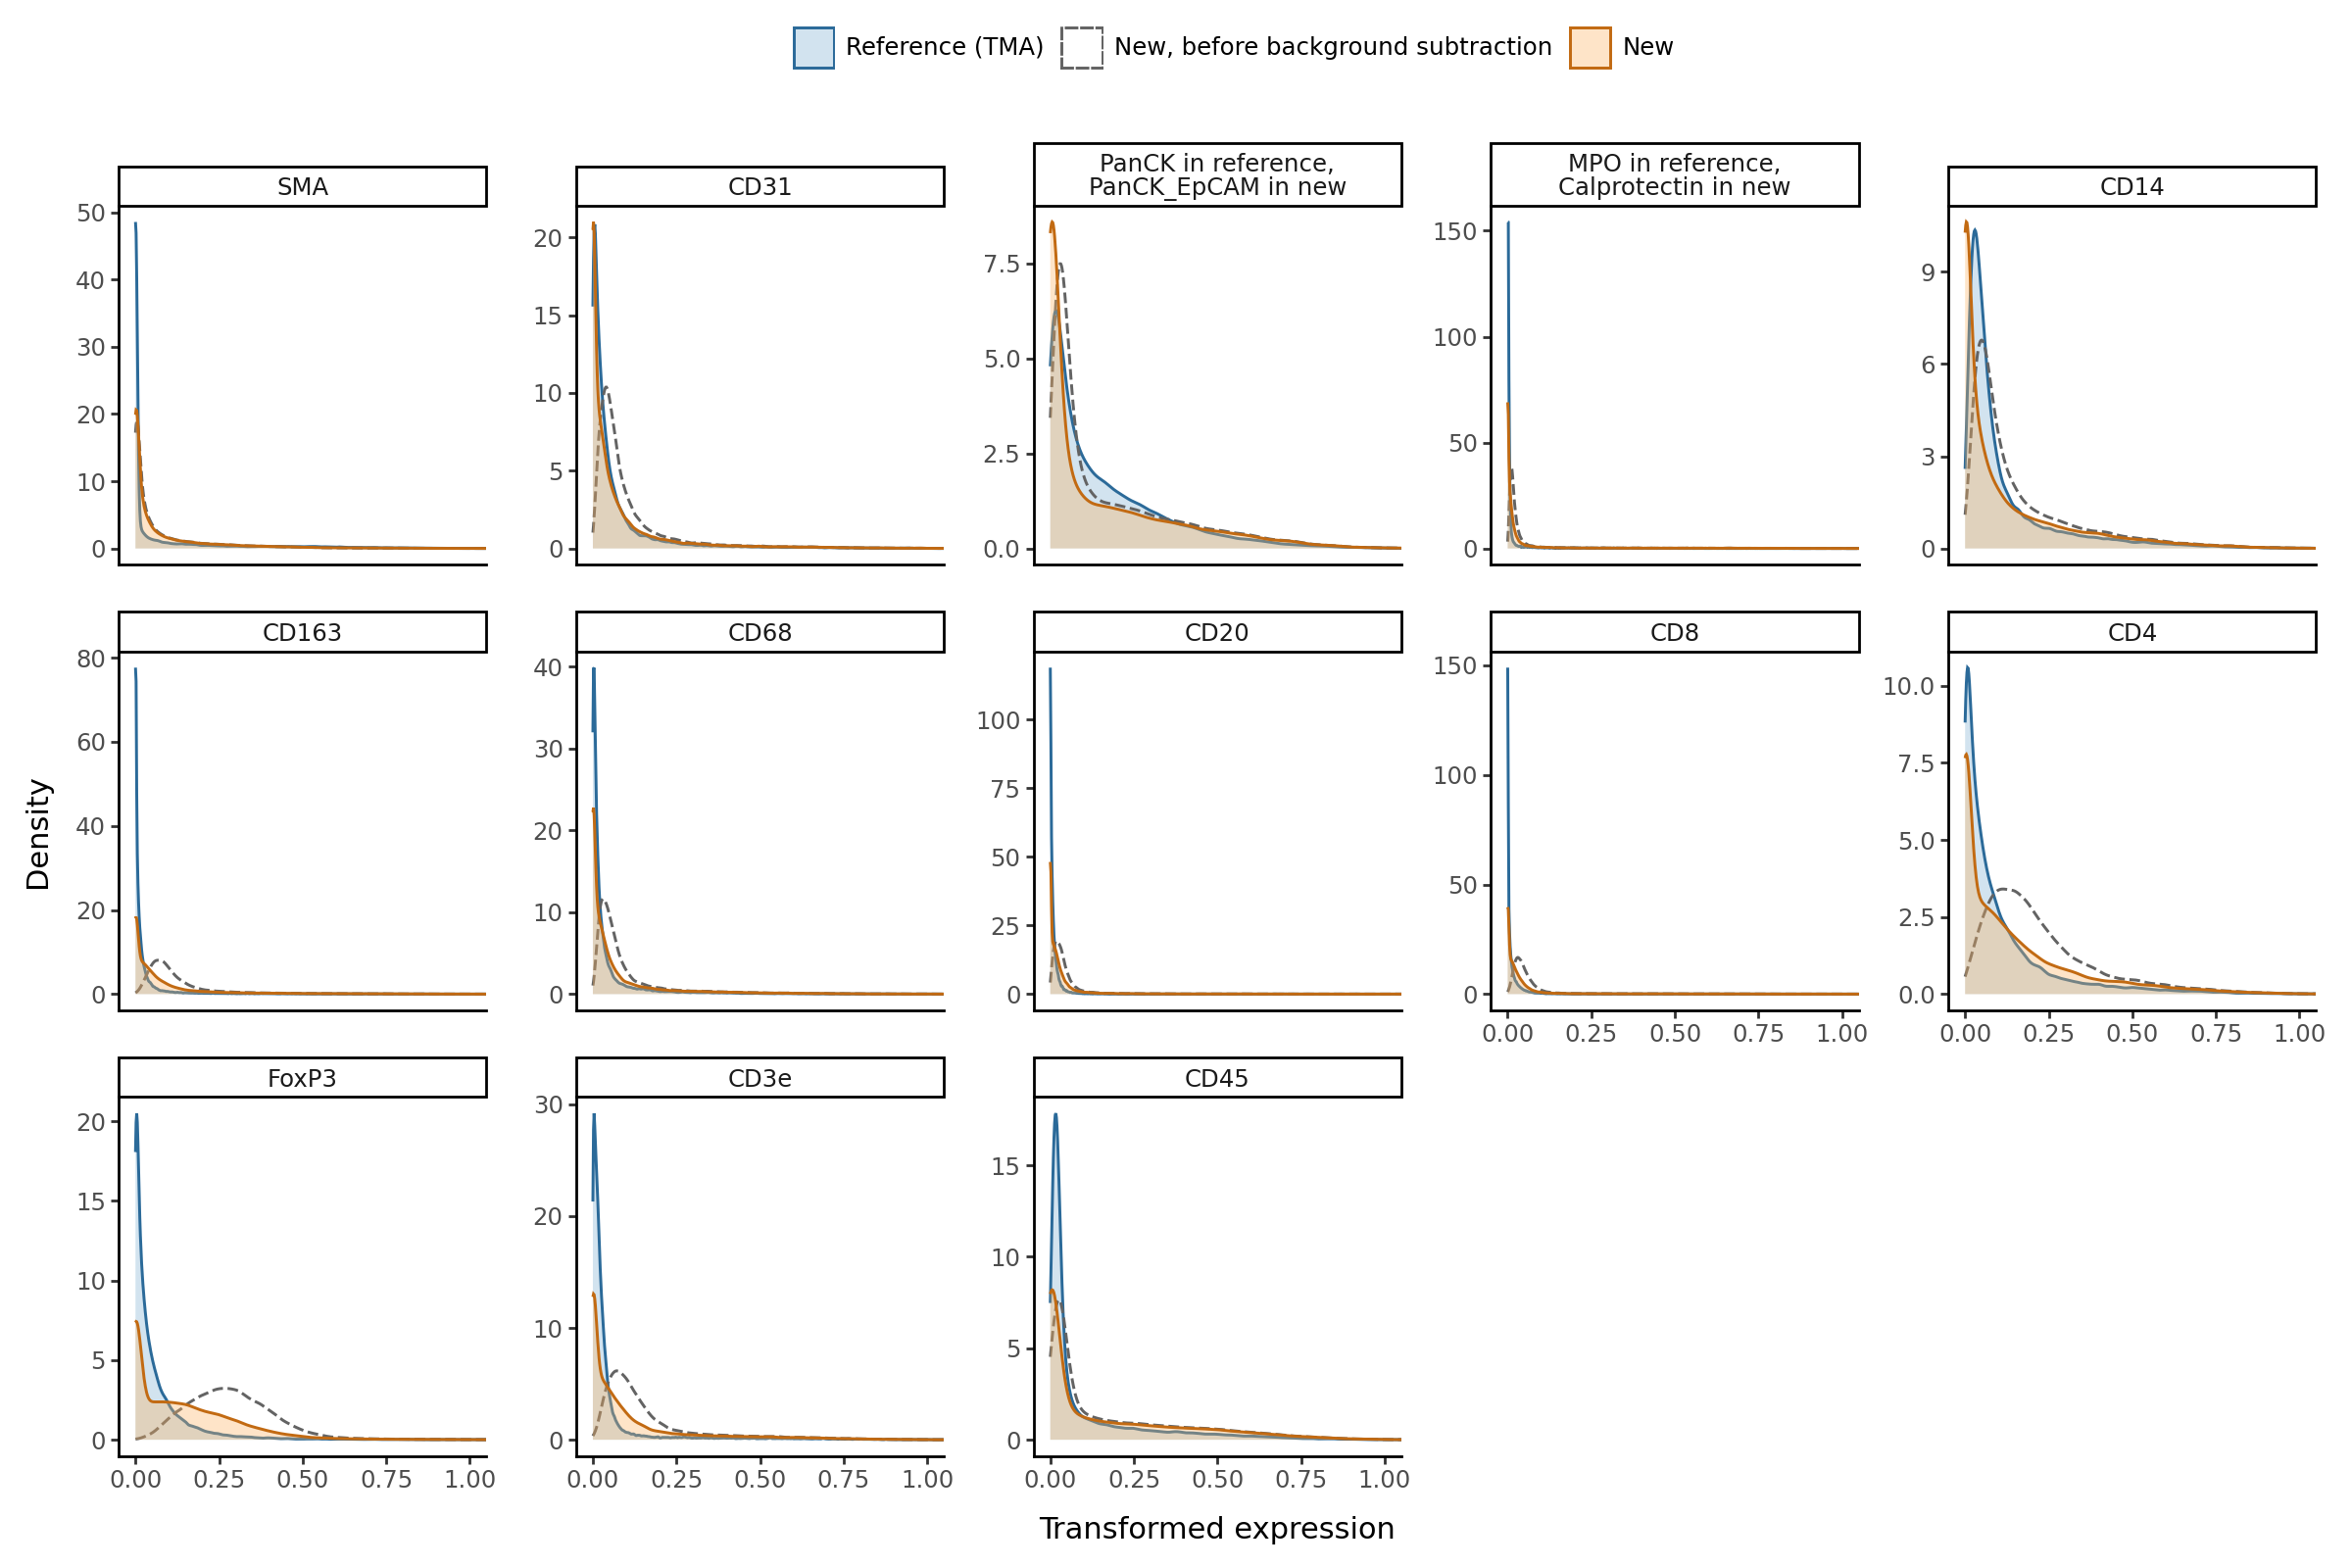

In [19]:
plot_df = pd.concat([
    ref_X.sample(50000, random_state=seed).assign(dataset="Reference (TMA)"),
    cells.rename(columns=new_to_ref)[shared_channels].sample(50000, random_state=seed).assign(dataset="New, before background subtraction"),
    new_X.sample(50000, random_state=seed).assign(dataset="New"),
]).melt(id_vars="dataset", var_name="marker", value_name="intensity")
plot_df["marker"] = pd.Categorical(plot_df["marker"].map(both_names), categories=[both_names[m] for m in markers_ordered])
plot_df["dataset"] = pd.Categorical(plot_df["dataset"], categories=["Reference (TMA)", "New, before background subtraction", "New"])

# Darker outlines of the dataset colors, and a dashed grey line for the values before background subtraction
line_colors = {"Reference (TMA)": "#2b6a99", "New, before background subtraction": "#636363", "New": "#c26a12"}
line_types = {"Reference (TMA)": "solid", "New, before background subtraction": "dashed", "New": "solid"}
fill_colors = {"Reference (TMA)": dataset_colors["Reference (TMA)"], "New, before background subtraction": "#ffffff00", "New": dataset_colors["New"]}

gp = (
    ggplot(plot_df, aes(x="intensity", color="dataset", fill="dataset", linetype="dataset"))
    + geom_density(alpha=0.35, size=0.6)
    + facet_wrap("~marker", scales="free_y", ncol=5)
    + scale_color_manual(values=line_colors)
    + scale_fill_manual(values=fill_colors)
    + scale_linetype_manual(values=line_types)
    + coord_cartesian(xlim=(0, 1))
    + theme_classic()
    + theme(legend_position="top", figure_size=(12, 8))
    + labs(x="Transformed expression", y="Density", color="", fill="", linetype="")
)
ggsave(gp, figure_dir + "marker_densities.pdf", width=12, height=8, verbose=False)
gp

## Train classifier
### Cross-validation on held-out FOVs of the reference
Each fold holds out a fifth of the reference FOVs, trains on the rest and predicts the held-out cells. These cells have real `MPO` and `PanCK` values, so this measures how well the classifier learns the consensus labels, not how well it transfers to the new panel.

In [20]:
encoder = LabelEncoder().fit(ref_labels)
y = encoder.transform(ref_labels)
type_order = [t for t in cell_types_ordered if t in encoder.classes_]

xgb_params = dict(n_estimators=300, max_depth=6, learning_rate=0.1,
                  tree_method="hist", n_jobs=-1, random_state=seed)
folds = list(GroupKFold(n_splits=5).split(ref_X, y, groups=ref.obs["fov"]))

def cross_validate(X, labels):
    """Class probabilities of each cell, predicted by a model that did not see its FOV"""
    encoder = LabelEncoder().fit(labels)
    y = encoder.transform(labels)
    proba = np.zeros((len(y), len(encoder.classes_)))
    for train, test in folds:
        model = XGBClassifier(**xgb_params).fit(X.iloc[train], y[train])
        proba[test] = model.predict_proba(X.iloc[test])
    return proba

cv_proba = cross_validate(ref_X, ref_labels)
ref_cv_labels = pd.Series(encoder.inverse_transform(cv_proba.argmax(axis=1)), index=ref_labels.index)

In [21]:
cv_report = pd.DataFrame(classification_report(ref_labels, ref_cv_labels, output_dict=True)).T
cv_report.loc[type_order + ["accuracy", "macro avg", "weighted avg"]].rename(index=display_name).round(3)

,precision,recall,f1-score,support
T reg cell,0.911,0.886,0.898,1926.000
CD4 Tcell,0.881,0.913,0.897,15340.000
CD8 Tcell,0.885,0.917,0.901,6824.000
NK cell,0.479,0.143,0.221,3973.000
B cell,0.938,0.953,0.946,3684.000
CD68 Macrophage,0.884,0.929,0.906,10775.000
CD163 Macrophage,0.886,0.939,0.912,10747.000
Other immune cell,0.796,0.693,0.741,17716.000
Monocyte,0.804,0.877,0.839,29922.000
Neutrophil,0.924,0.969,0.946,19169.000


Fraction of the cells of each consensus type, on the rows, given each predicted label:

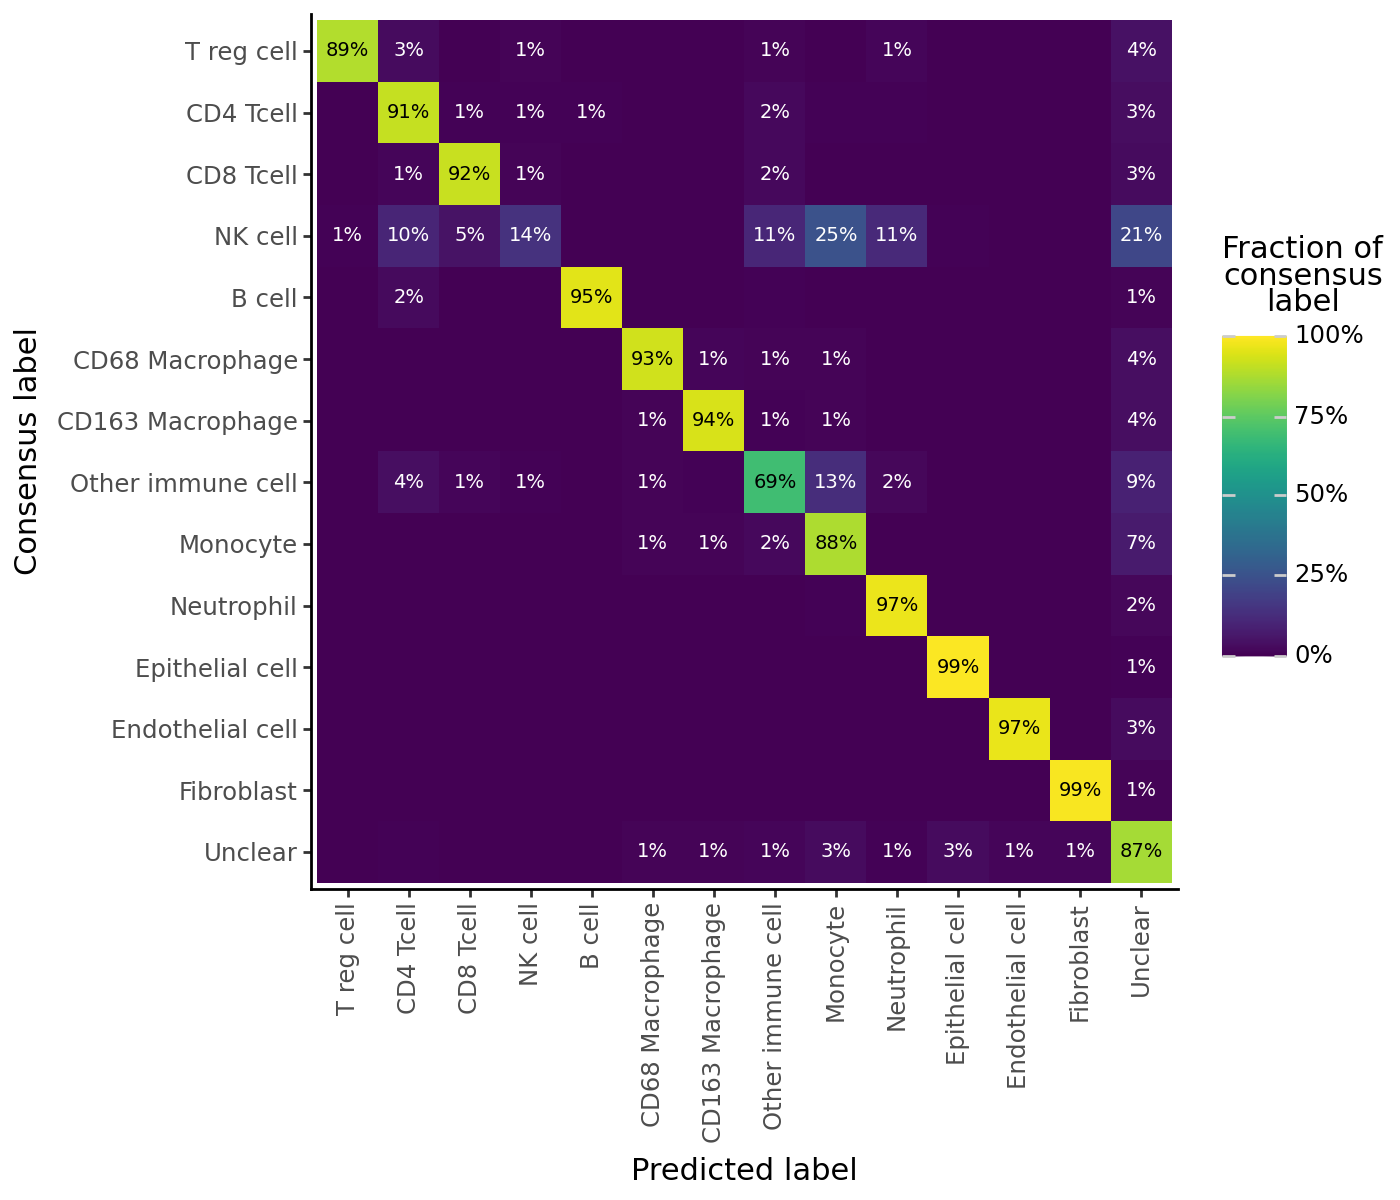

In [22]:
confmat = pd.crosstab(ref_labels, ref_cv_labels).stack().rename("Count").reset_index()
confmat.columns = ["Consensus", "Predicted", "Count"]
confmat["Fraction"] = confmat["Count"] / confmat.groupby("Consensus")["Count"].transform("sum")
confmat["Consensus"] = display_types(confmat["Consensus"], type_order[::-1])
confmat["Predicted"] = display_types(confmat["Predicted"], type_order)
confmat = tile_labels(confmat)

gp = (
    ggplot(confmat, aes(x="Predicted", y="Consensus"))
    + geom_tile(aes(fill="Fraction"))
    + geom_text(aes(label="label", color="text_color"), size=7)
    + scale_fill_cmap(cmap_name="viridis", limits=(0, 1), labels=percent_labels)
    + scale_color_identity()
    + theme_classic()
    + theme(axis_text_x=element_text(angle=90), figure_size=(7, 6))
    + labs(x="Predicted label", y="Consensus label", fill="Fraction of\nconsensus\nlabel")
)
ggsave(gp, figure_dir + "cv_confusion_matrix.pdf", width=7, height=6, verbose=False)
gp

## Transfer to the new dataset

In [23]:
model = XGBClassifier(**xgb_params).fit(ref_X, y)
new_proba = model.predict_proba(new_X)
new_labels = pd.Series(encoder.inverse_transform(new_proba.argmax(axis=1)), index=new_X.index)
new_confidence = pd.Series(new_proba.max(axis=1), index=new_X.index)
new_labels.value_counts().rename(index=display_name)

Epithelial cell      232740
Unclear              149399
Fibroblast            63922
Endothelial cell      37986
CD4 Tcell             34696
Monocyte              34592
Neutrophil            31331
Other immune cell     29187
CD163 Macrophage      22602
CD8 Tcell             18162
CD68 Macrophage       14995
B cell                 5994
T reg cell             5005
NK cell                2430
Name: count, dtype: int64

### Cell type proportions
The new dataset is shown as a whole and split by region, tumor core or invasive margin. The second plot shows the regions only, with cell types in order of abundance in the reference, as in the cell count plot of `lineage/CellTypeViz.ipynb`. The invasive margin should hold fewer cancer cells and more immune cells than the tumor core.

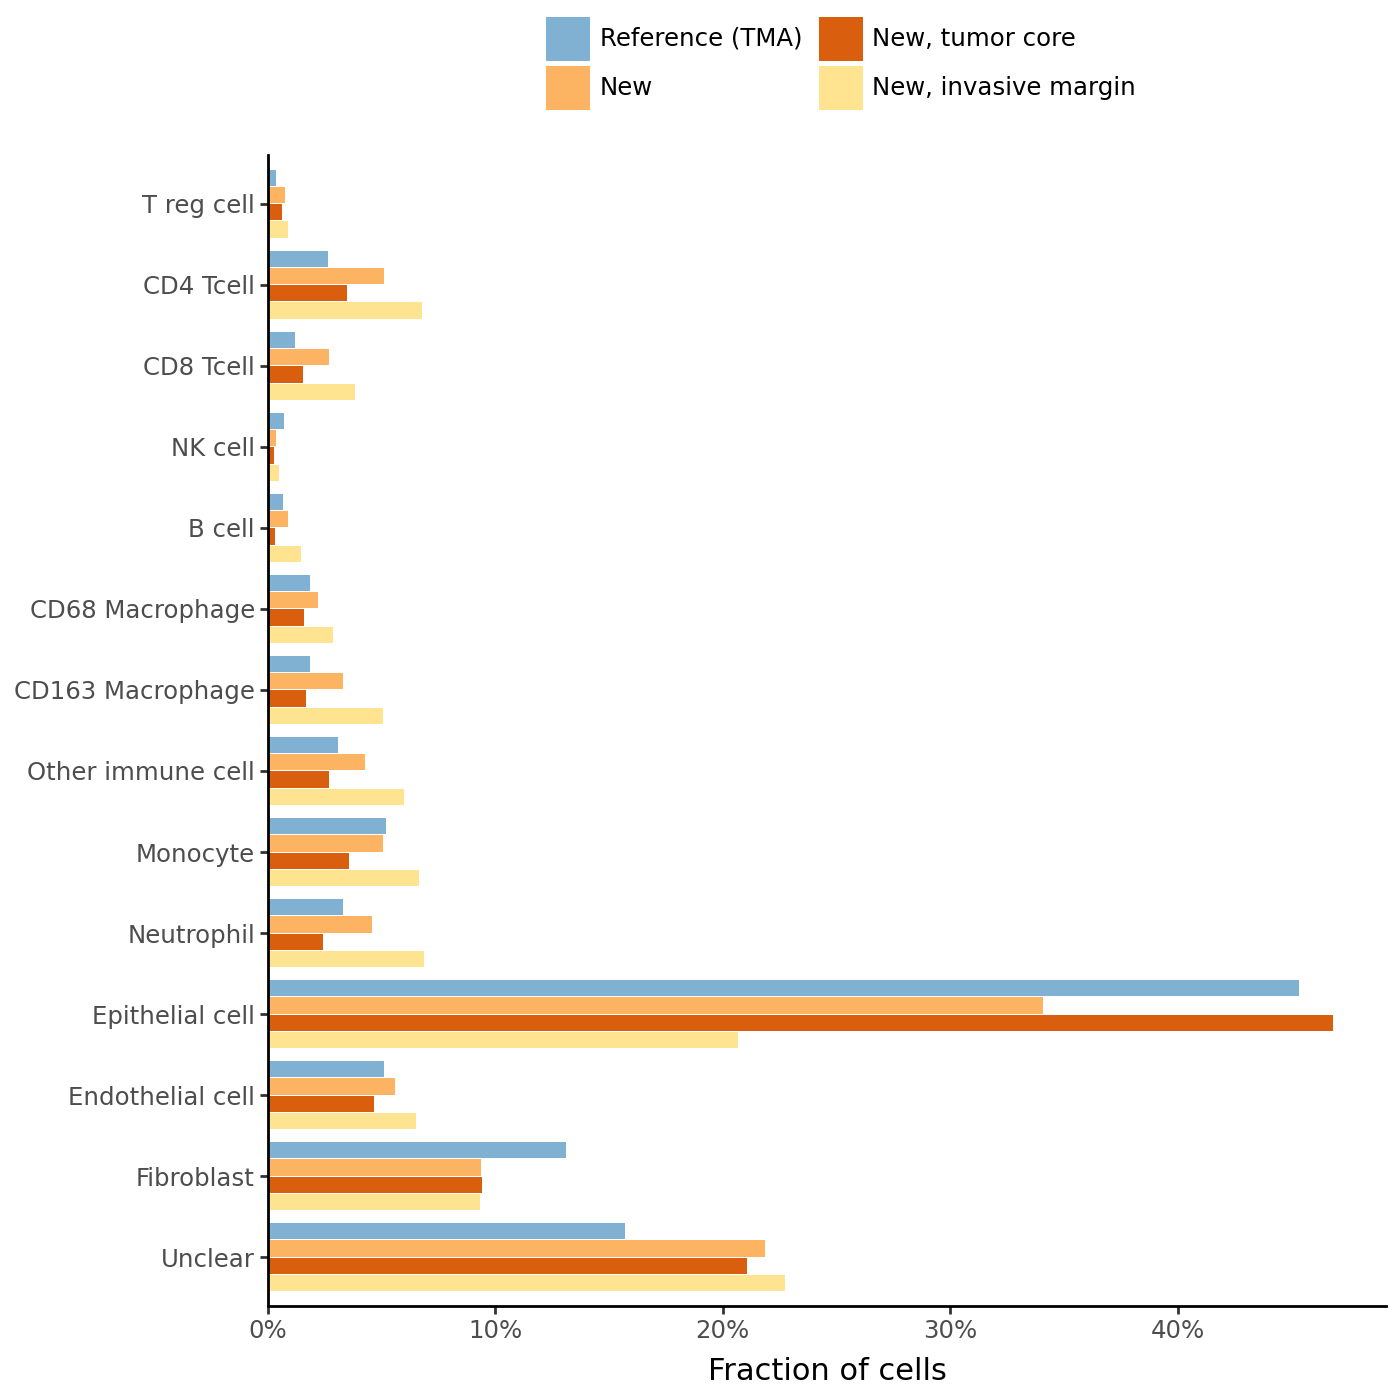

In [24]:
new_region = cells["fov"].str.extract(r"_(TC|IM)_", expand=False)

def type_proportions(labels, dataset):
    return labels.value_counts(normalize=True).rename_axis("cell_type").rename("proportion").reset_index().assign(dataset=dataset)

prop_df = pd.concat([
    type_proportions(ref_labels, "Reference (TMA)"),
    type_proportions(new_labels, "New"),
    type_proportions(new_labels[new_region == "TC"], "New, tumor core"),
    type_proportions(new_labels[new_region == "IM"], "New, invasive margin"),
])
prop_df["cell_type"] = display_types(prop_df["cell_type"], type_order[::-1])
prop_df["dataset"] = pd.Categorical(prop_df["dataset"], categories=list(dataset_colors)[:4][::-1])

gp = (
    ggplot(prop_df, aes(x="cell_type", y="proportion", fill="dataset"))
    + geom_col(position=position_dodge(width=0.85), width=0.8)
    + coord_flip()
    + scale_fill_manual(values=dataset_colors)
    + guides(fill=guide_legend(nrow=2, reverse=True))
    + scale_y_continuous(labels=percent_labels, expand=(0, 0, 0.05, 0))
    + theme_classic()
    + theme(legend_position="top", figure_size=(7, 7))
    + labs(x="", y="Fraction of cells", fill="")
)
ggsave(gp, figure_dir + "cell_type_proportions.pdf", width=7, height=7, verbose=False)
gp

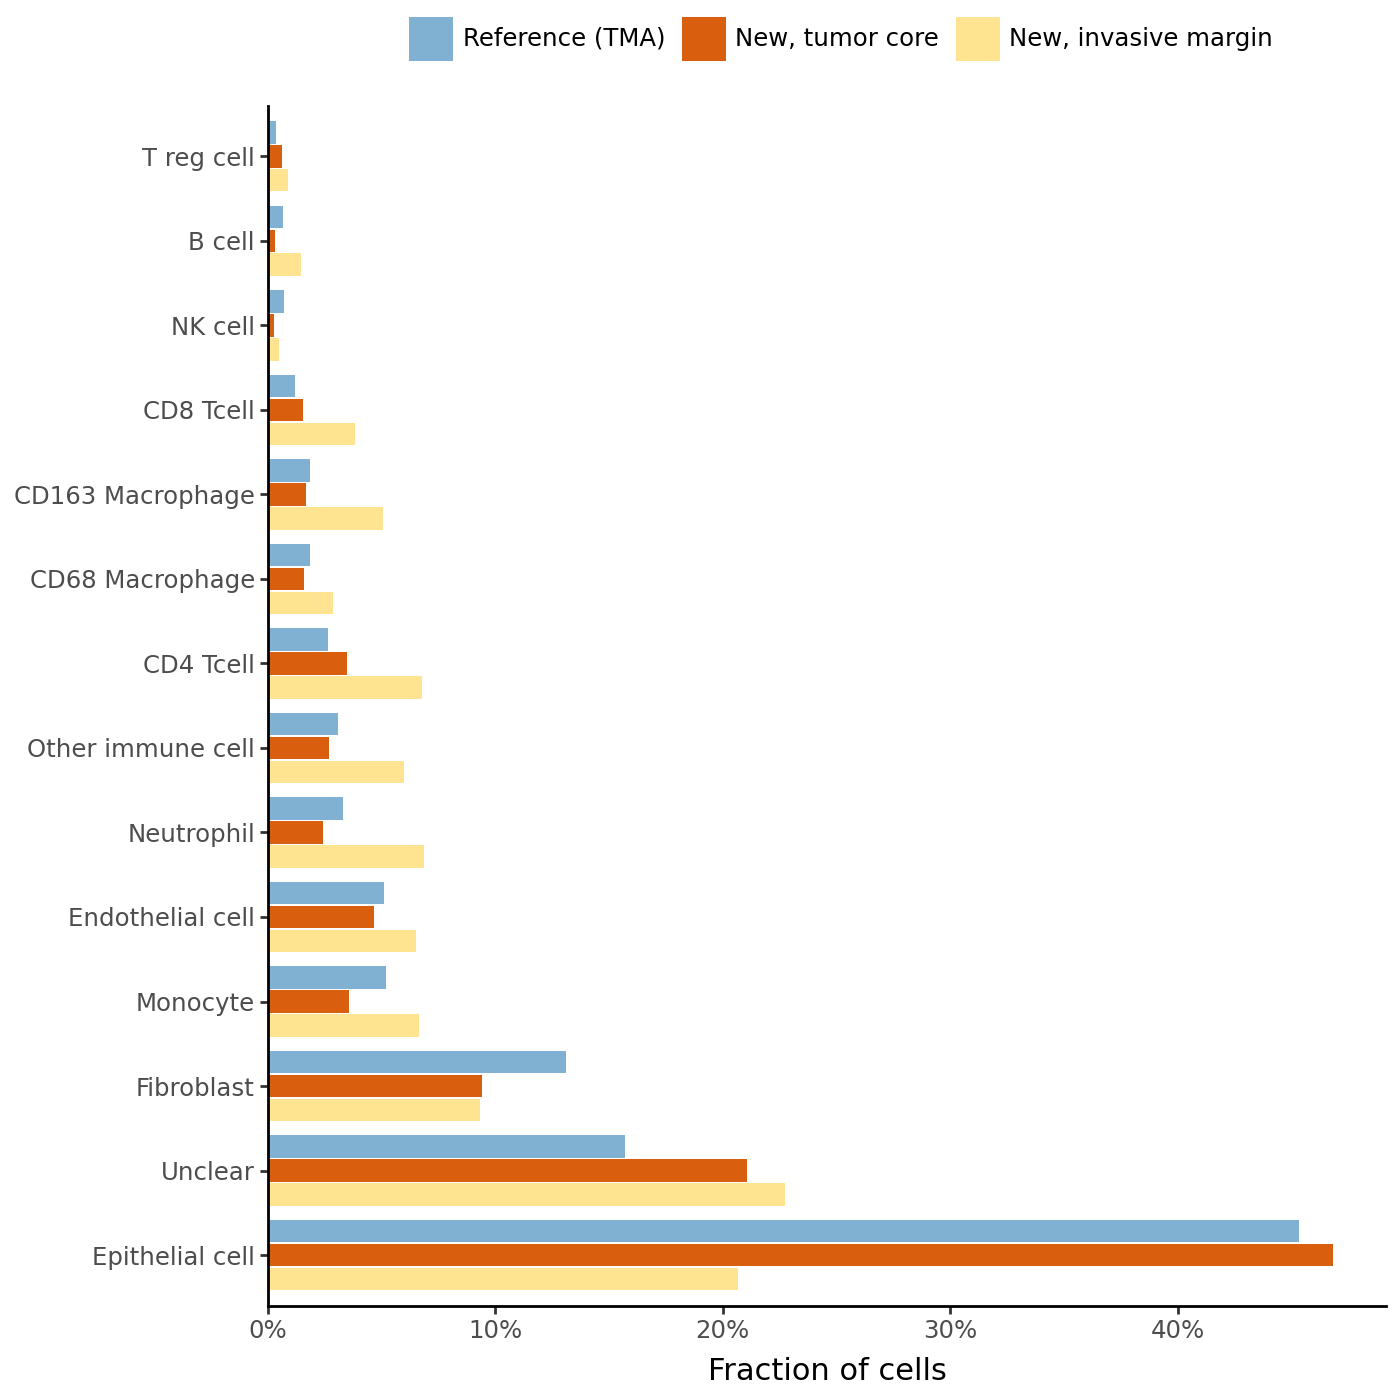

In [25]:
region_prop = pd.concat([
    type_proportions(ref_labels, "Reference (TMA)"),
    type_proportions(new_labels[new_region == "TC"], "New, tumor core"),
    type_proportions(new_labels[new_region == "IM"], "New, invasive margin"),
])
region_prop["cell_type"] = display_types(region_prop["cell_type"], ref_labels.value_counts().index)
region_prop["dataset"] = pd.Categorical(region_prop["dataset"], categories=["New, invasive margin", "New, tumor core", "Reference (TMA)"])

gp = (
    ggplot(region_prop, aes(x="cell_type", y="proportion", fill="dataset"))
    + geom_col(position=position_dodge(width=0.85), width=0.8)
    + coord_flip()
    + scale_fill_manual(values=dataset_colors)
    + guides(fill=guide_legend(reverse=True))
    + scale_y_continuous(labels=percent_labels, expand=(0, 0, 0.05, 0))
    + theme_classic()
    + theme(legend_position="top", figure_size=(7, 7))
    + labs(x="", y="Fraction of cells", fill="")
)
ggsave(gp, figure_dir + "cell_type_proportions_by_region.pdf", width=7, height=7, verbose=False)
gp

## Are the transferred populations coherent?
### Lineage channels used by the classifier
Median expression of each lineage marker per cell type, as in `lineage/CellTypeViz.ipynb`. Reference cells have their consensus label and new cells their transferred label. Each panel names the channels of its own dataset. `Unclear` cells are left out.

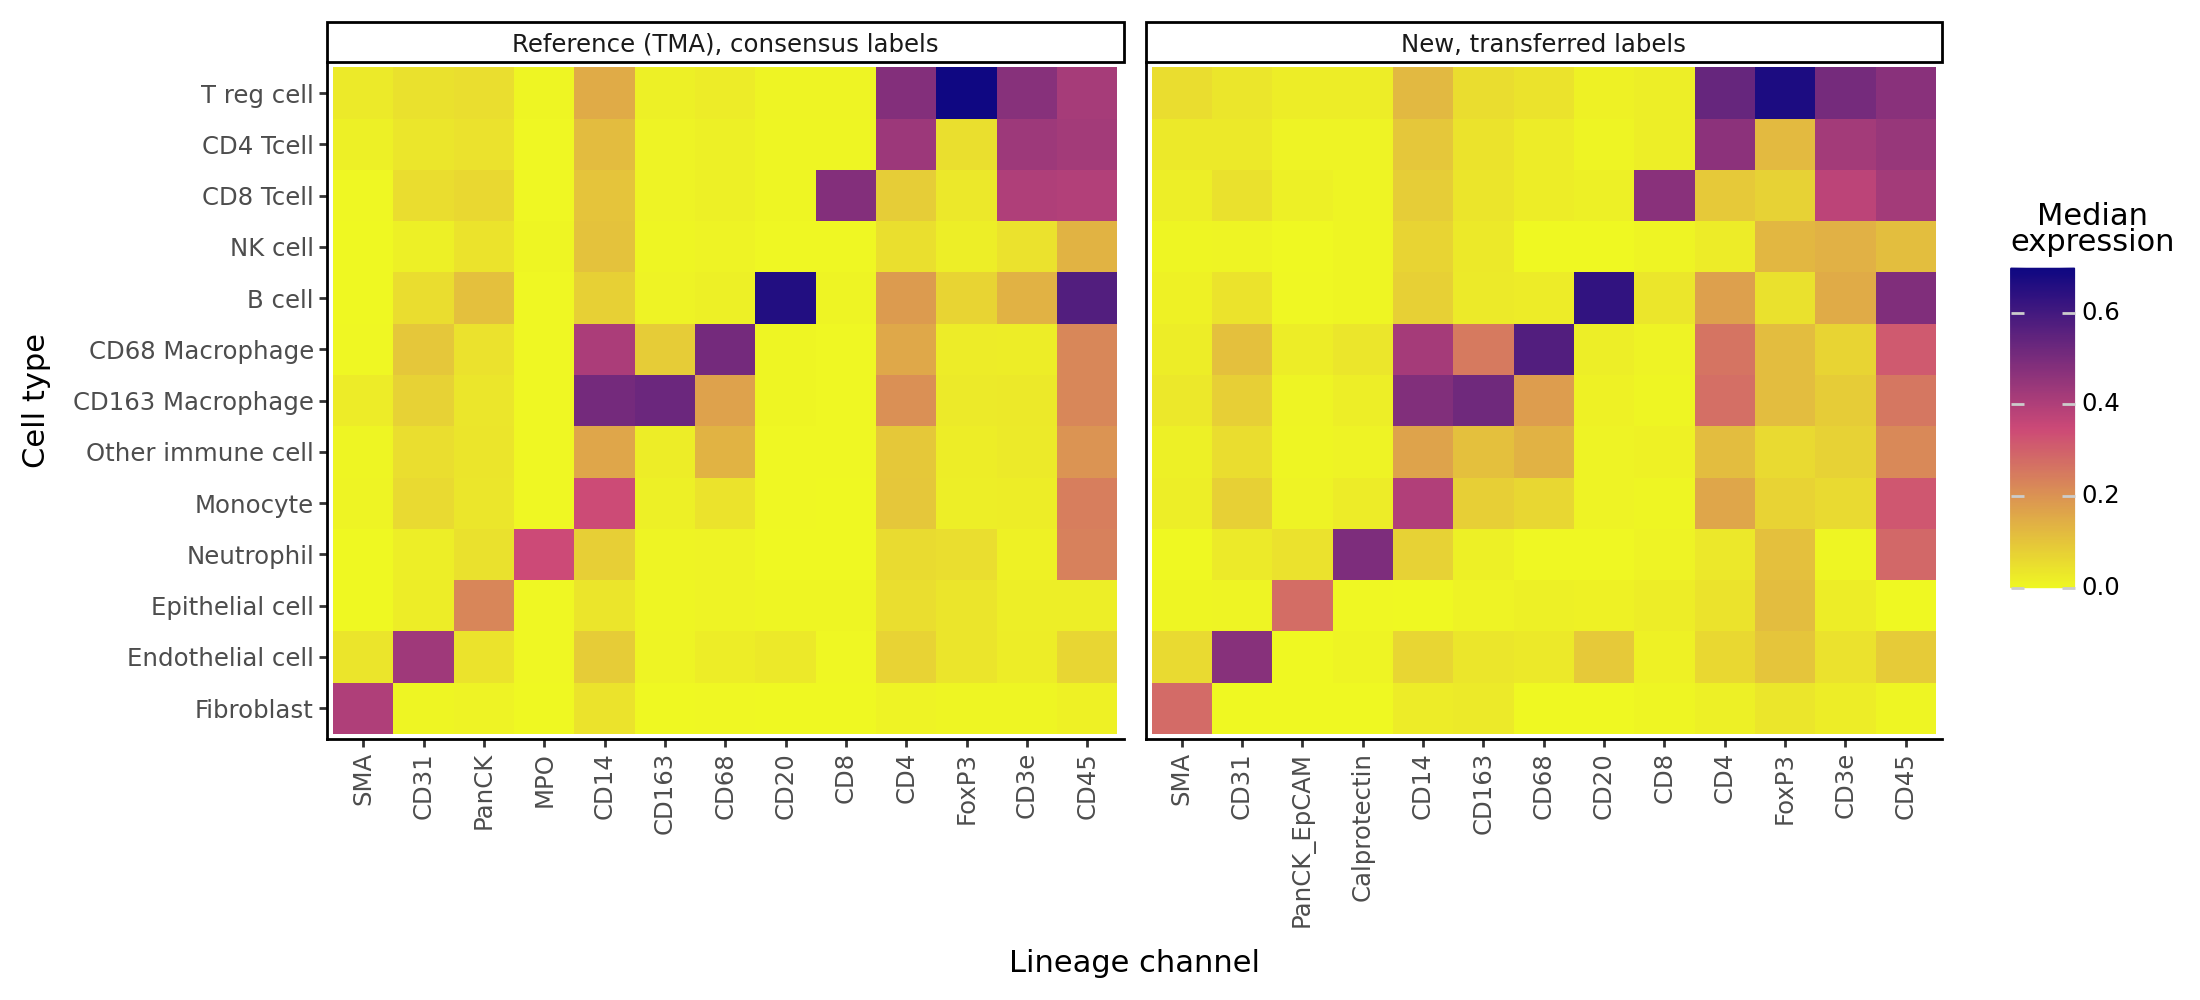

In [26]:
def median_profiles(X, labels, dataset):
    medians = X.groupby(labels.values).median().drop(index="Unclear", errors="ignore")
    return medians.melt(ignore_index=False, var_name="channel", value_name="median").rename_axis("cell_type").reset_index().assign(dataset=dataset)

heatmap_df = pd.concat([
    median_profiles(ref_X, ref_labels, "Reference (TMA), consensus labels"),
    median_profiles(new_panel_X, new_labels, "New, transferred labels"),
])
# Each channel stays at the position of the marker it measures
channel_order = list(dict.fromkeys(c for m in markers_ordered for c in (m, new_channel(m))))
heatmap_df["channel"] = pd.Categorical(heatmap_df["channel"], categories=channel_order)
heatmap_df["cell_type"] = display_types(heatmap_df["cell_type"], [t for t in type_order if t != "Unclear"][::-1])
heatmap_df["dataset"] = pd.Categorical(heatmap_df["dataset"], categories=["Reference (TMA), consensus labels", "New, transferred labels"])

gp = (
    ggplot(heatmap_df, aes(x="channel", y="cell_type"))
    + geom_tile(aes(fill="median"))
    + facet_wrap("~dataset", scales="free_x")
    + scale_fill_gradientn(colors=plasma_reversed)
    + theme_classic()
    + theme(axis_text_x=element_text(angle=90), figure_size=(11, 5))
    + labs(x="Lineage channel", y="Cell type", fill="Median\nexpression")
)
ggsave(gp, figure_dir + "heatmap_lineage_markers.pdf", width=11, height=5, verbose=False)
gp

Distribution of each lineage marker per cell type. Points show the median. At most 2000 cells per cell type and dataset are drawn.

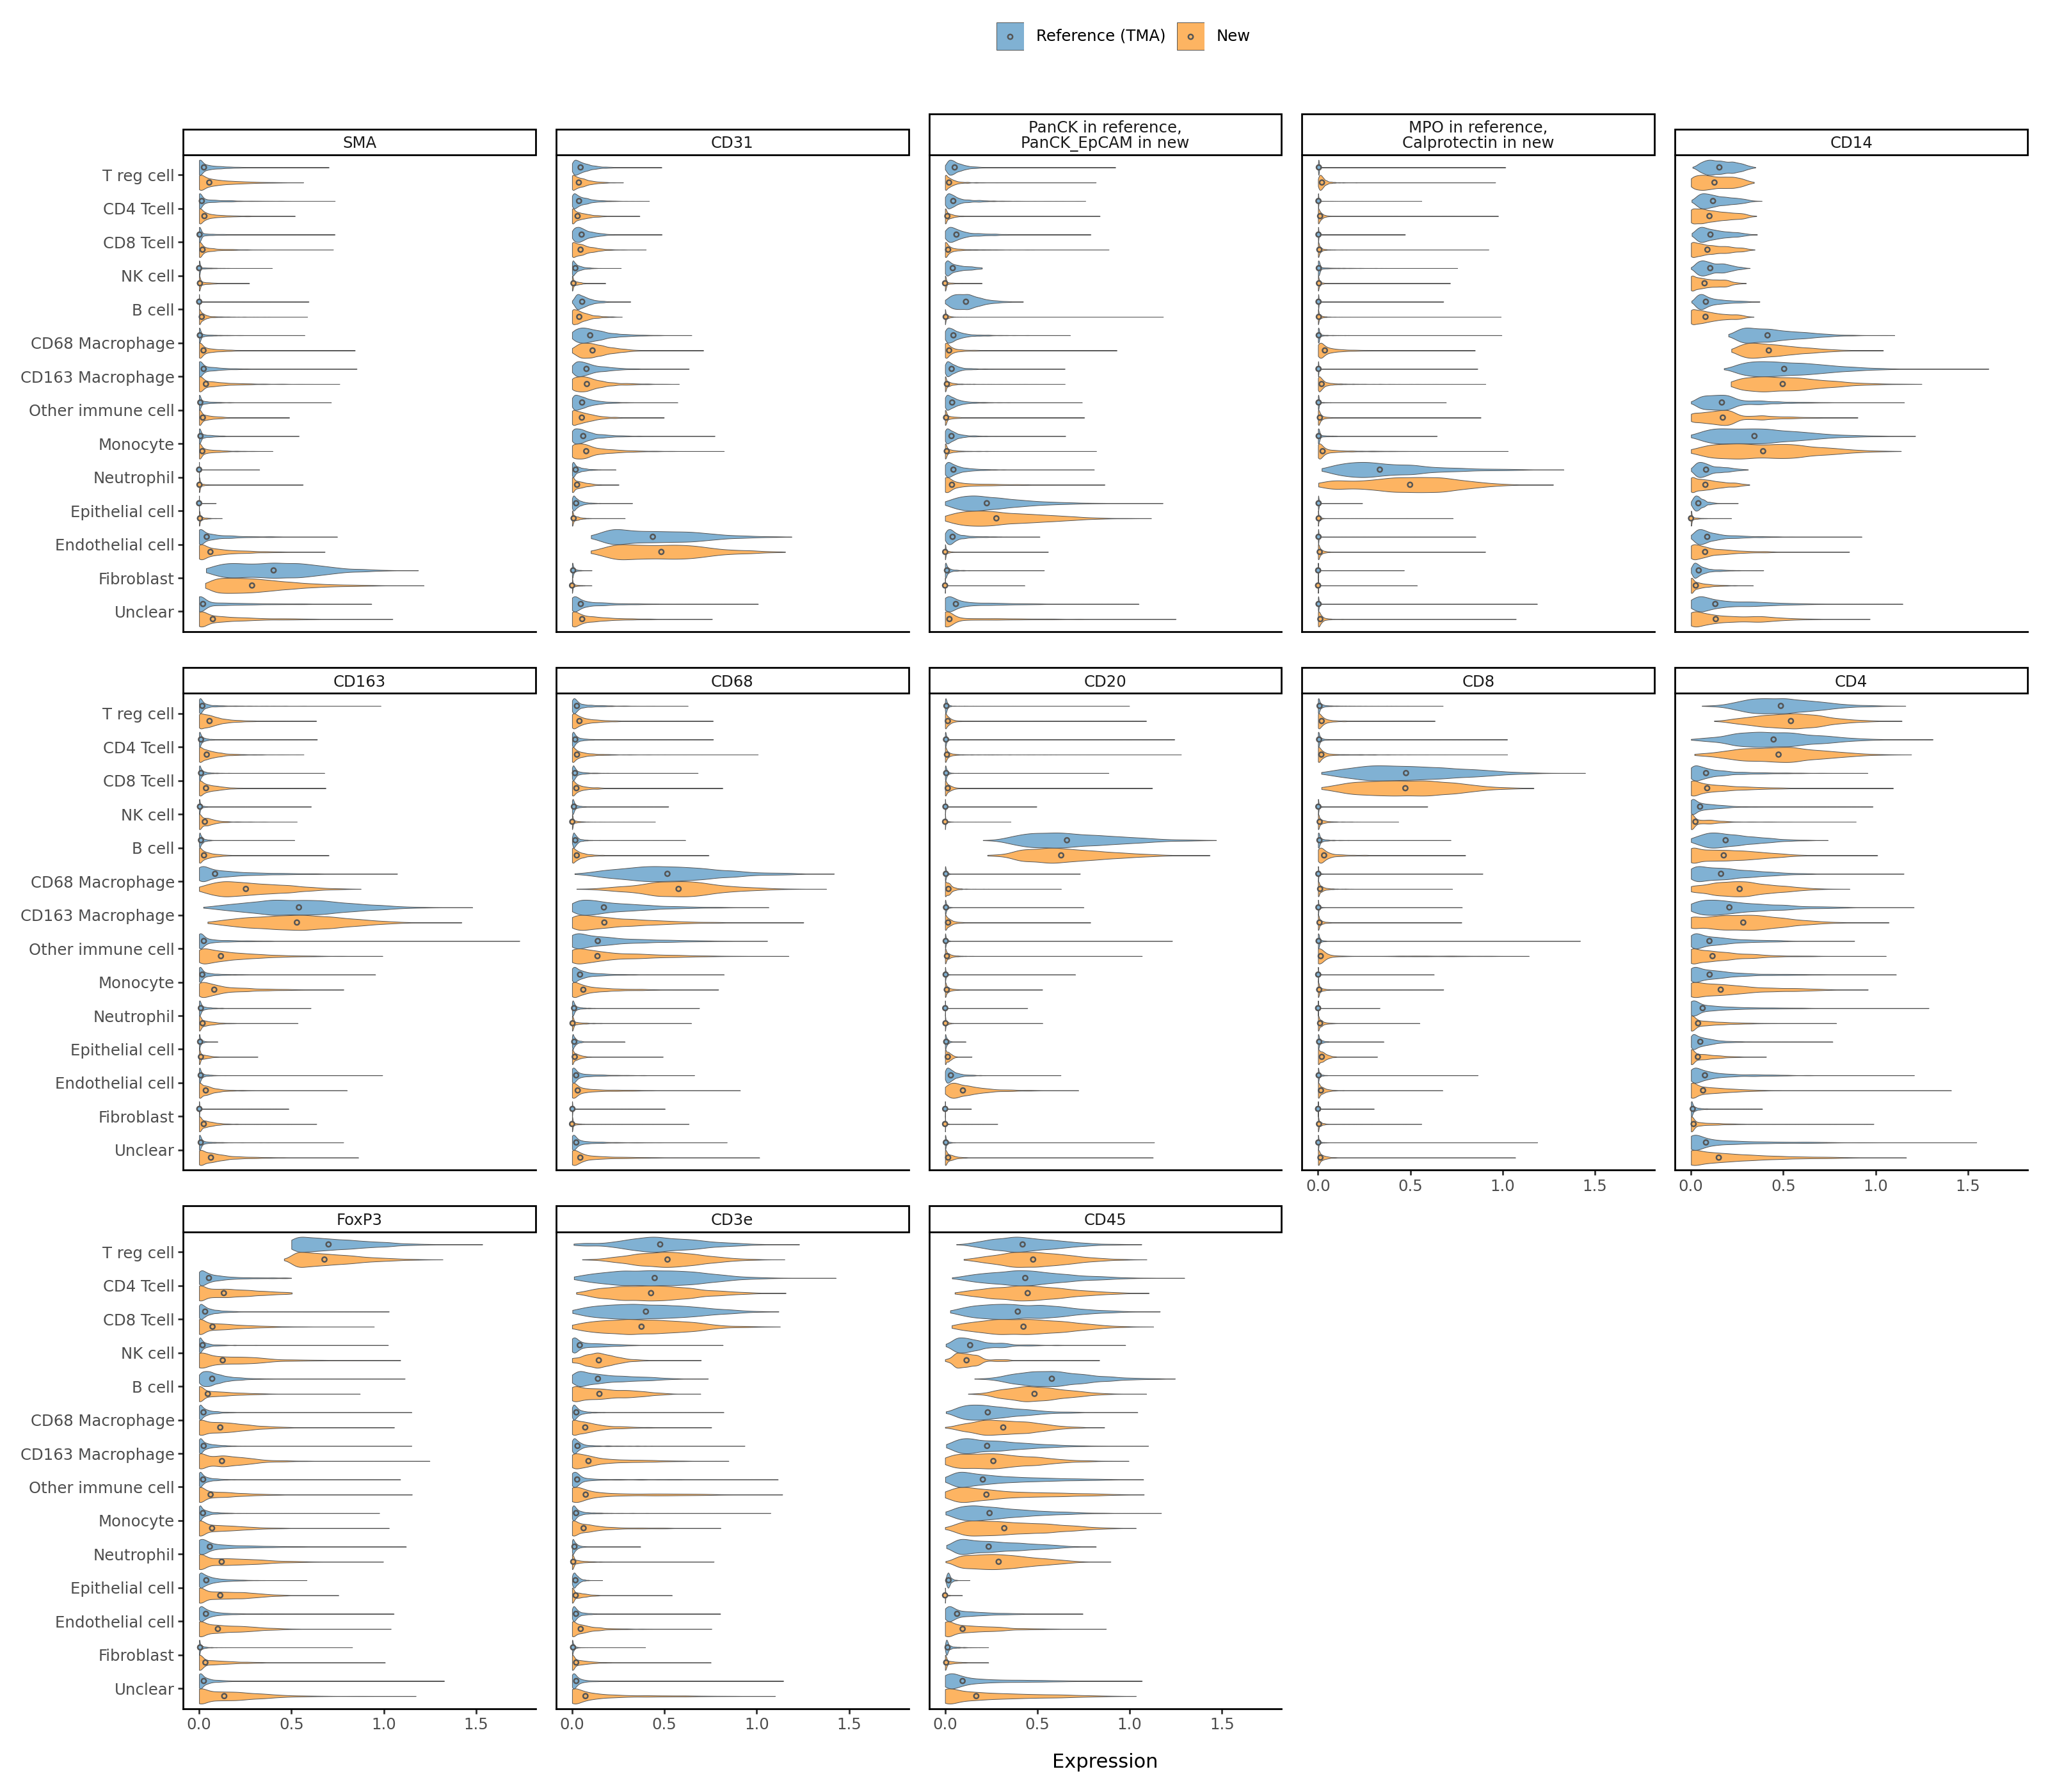

In [27]:
def sample_per_type(X, labels, n=2000):
    """Subsample at most `n` cells per cell type"""
    return X.assign(cell_type=labels.values).sample(frac=1, random_state=seed).groupby("cell_type").head(n)

def violins_per_type(ref_df, new_df, panel_names, ncol, figure_size):
    """Violins per cell type and dataset, one panel per entry of panel_names"""
    plot_df = pd.concat([ref_df.assign(dataset="Reference (TMA)"), new_df.assign(dataset="New")])
    plot_df = plot_df.melt(id_vars=["cell_type", "dataset"], var_name="marker", value_name="expression").dropna()
    plot_df["marker"] = pd.Categorical(plot_df["marker"].map(panel_names), categories=list(panel_names.values()))
    plot_df["cell_type"] = display_types(plot_df["cell_type"], type_order[::-1])
    plot_df["dataset"] = pd.Categorical(plot_df["dataset"], categories=["New", "Reference (TMA)"])
    dodge = position_dodge(width=0.9)
    return (
        ggplot(plot_df, aes(x="cell_type", y="expression", fill="dataset"))
        + geom_violin(scale="width", color="#555555", size=0.2, position=dodge)
        + stat_summary(fun_y=np.median, geom="point", color="#555555", size=1, position=dodge)
        + facet_wrap("~marker", ncol=ncol)
        + coord_flip()
        + scale_fill_manual(values=dataset_colors)
        + guides(fill=guide_legend(reverse=True))
        + theme_classic()
        + theme(legend_position="top", figure_size=figure_size)
        + labs(x="", y="Expression", fill="")
    )

gp = violins_per_type(sample_per_type(ref_X, ref_labels), sample_per_type(new_X, new_labels),
                      both_names, ncol=5, figure_size=(16, 14))
ggsave(gp, figure_dir + "violin_lineage_markers.pdf", width=16, height=14, verbose=False)
gp

For each dataset, the mean marker levels per cell type are z-scored per marker across cell types. The heatmap shows the Spearman correlation of these profiles between datasets. It compares the ranking of markers within a profile, so one very high marker, such as `PanCK` in cancer cells, cannot dominate it. Matching populations should lie on the diagonal.

In [28]:
def type_profiles(X, labels):
    profiles = X.groupby(labels.values).mean()
    return (profiles - profiles.mean()) / profiles.std()

ref_profiles = type_profiles(ref_X, ref_labels)
new_profiles = type_profiles(new_X, new_labels)
common_types = [t for t in type_order if t in new_profiles.index]

profile_corr = pd.DataFrame(
    [[spearmanr(ref_profiles.loc[r], new_profiles.loc[n])[0] for n in common_types] for r in common_types],
    index=common_types, columns=common_types)
pd.Series(np.diag(profile_corr), index=[display_name(t) for t in common_types]).sort_values().round(3)

B cell               0.533
Neutrophil           0.764
NK cell              0.841
Fibroblast           0.918
CD4 Tcell            0.929
Monocyte             0.929
Other immune cell    0.934
T reg cell           0.940
Unclear              0.951
Endothelial cell     0.962
CD68 Macrophage      0.967
CD8 Tcell            0.973
CD163 Macrophage     0.973
Epithelial cell      0.978
dtype: float64

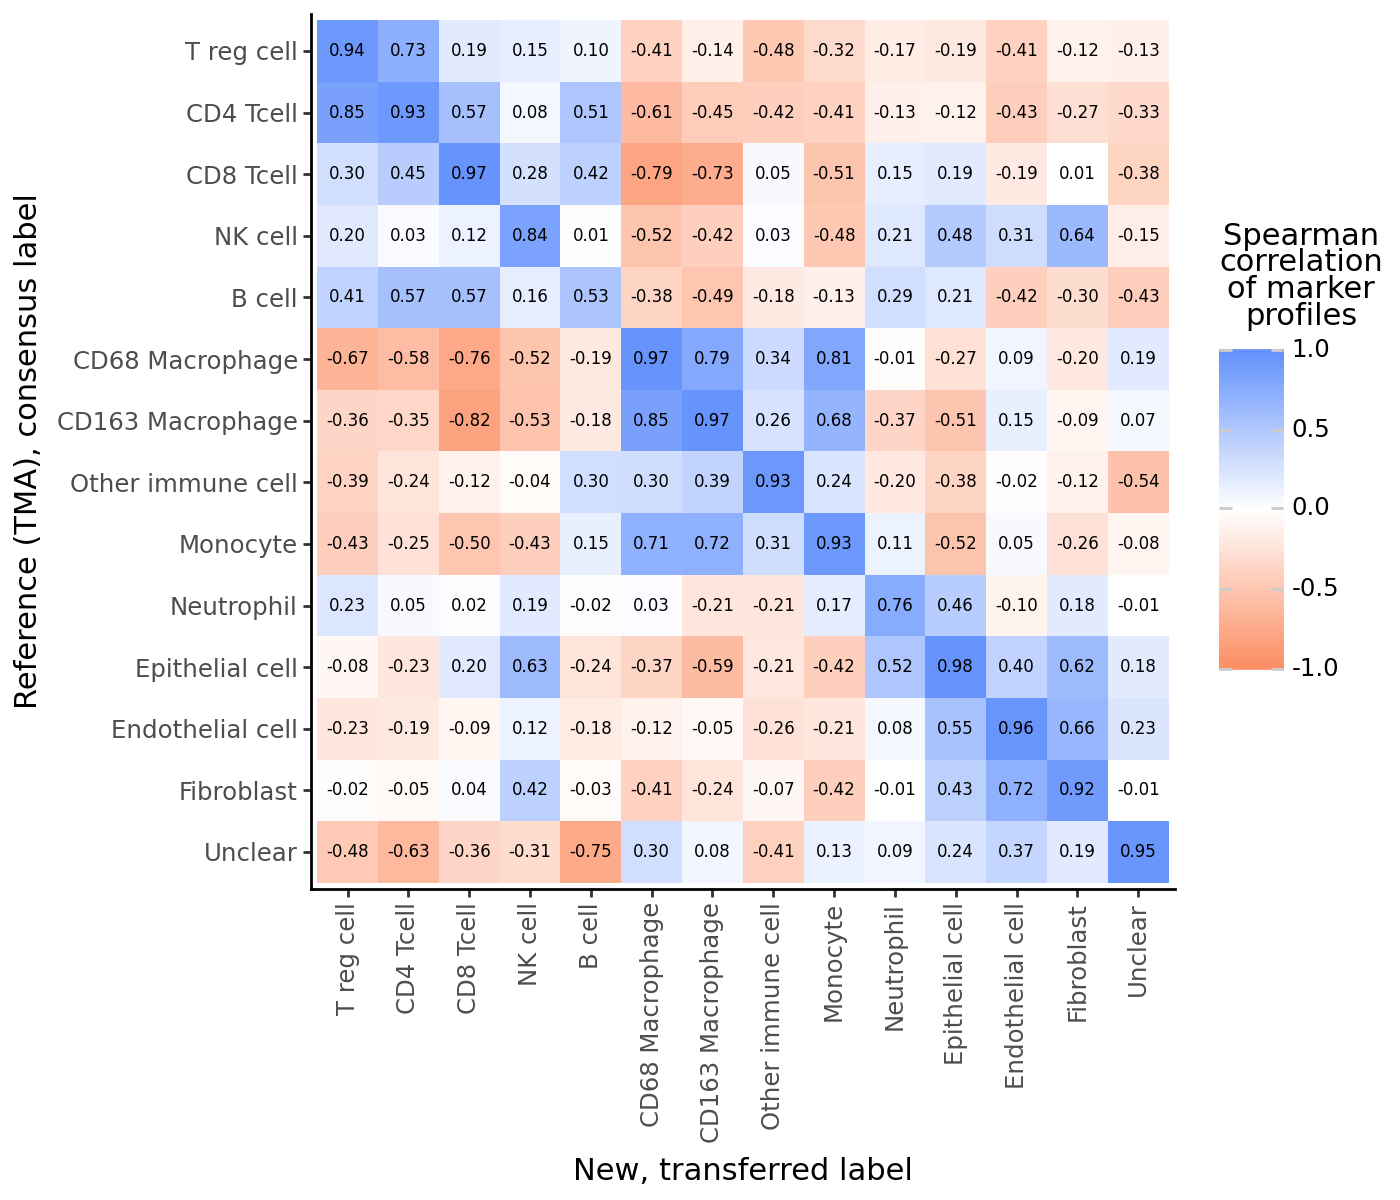

In [29]:
corr_df = profile_corr.stack().rename("Correlation").reset_index()
corr_df.columns = ["Reference", "New", "Correlation"]
corr_df["Reference"] = display_types(corr_df["Reference"], common_types[::-1])
corr_df["New"] = display_types(corr_df["New"], common_types)
corr_df["label"] = corr_df["Correlation"].map(lambda r: f"{r:.2f}")

gp = (
    ggplot(corr_df, aes(x="New", y="Reference"))
    + geom_tile(aes(fill="Correlation"))
    + geom_text(aes(label="label"), size=6)
    + scale_fill_correlation()
    + theme_classic()
    + theme(axis_text_x=element_text(angle=90), figure_size=(7, 6))
    + labs(x="New, transferred label", y="Reference (TMA), consensus label", fill="Spearman\ncorrelation\nof marker\nprofiles")
)
ggsave(gp, figure_dir + "profile_correlation.pdf", width=7, height=6, verbose=False)
gp

Every transferred population correlates best with its own reference type. The lowest values come from markers that are low in both datasets. Reference B cells have more `PanCK` than new B cells have `PanCK_EpCAM`, 0.12 against 0.01 on average. As a result, reference B cells correlate slightly better with transferred CD4 T cells, at 0.57, than with transferred B cells, at 0.53. Neutrophils reach 0.76, because new neutrophils have more `PanCK_EpCAM` than reference neutrophils have `PanCK`. NK cells reach 0.84.

#### Agreement with rule-based gating
This applies the highest-value gating of `Annotation_gating_Hamburg.ipynb` to both datasets, using only the shared channels. A label agrees with the gating if the rules of `determine_cell_type` in `Pyflowsome_clustering_Hamburg.ipynb` and `consensus_dict` in `annotation_consensus.ipynb` can turn the gating outcome into that label. The threshold refinements of `Pyflowsome_clustering_Hamburg.ipynb` are left out, so the reference shows how much agreement to expect. The check skips `Unclear` cells and NK cells, which the original gating identified with `CD7`.

In [30]:
def hierarchical_gating(X):
    """Highest-value gating of Annotation_gating_Hamburg.ipynb on available channels"""
    step1 = [c for c in ["SMA", "CD31", "CD163", "CD68", "CD8", "CD45", "PanCK", "MPO", "CD7"] if c in X.columns]
    step2 = [c for c in ["CD3e", "CD8", "CD7", "CD14", "MPO", "CD20", "CD68", "CD163", "HLADRa"] if c in X.columns]
    step3 = [c for c in ["CD4", "CD8", "CD7"] if c in X.columns]

    gating = X[step1].idxmax(axis=1)
    is_cd45 = gating == "CD45"
    gating[is_cd45] = X.loc[is_cd45, step2].idxmax(axis=1)
    is_cd3e = gating == "CD3e"
    gating[is_cd3e] = X.loc[is_cd3e, step3].idxmax(axis=1)
    return gating

# Consensus labels which can result from each gating outcome
rule_compatible = {
    "PanCK": ["Cancer_cell"],
    "SMA": ["CAF", "Cancer_cell"],
    "CD31": ["Endothelial_cell", "Cancer_cell"],
    "CD4": ["CD4_Tcell", "T_reg_cell"],
    "CD8": ["CD8_Tcell"],
    "CD68": ["CD68_Macrophage"],
    "CD163": ["CD163_Macrophage"],
    "CD14": ["Monocyte"],
    "MPO": ["Neutrophil"],
    "CD20": ["B_cell"],
}
# Immune cells not further resolved, including APCs here
for gate in ["CD4", "CD8", "CD68", "CD163", "CD14", "MPO", "CD20"]:
    rule_compatible[gate].append("Other_immune_cell")

def rule_agreement(labels, gating):
    agree = pd.Series([lab in rule_compatible[g] for lab, g in zip(labels, gating)], index=labels.index)
    return agree[~labels.isin(["Unclear", "NK_cell"])]

ref_gating = hierarchical_gating(ref_X)
new_gating = hierarchical_gating(new_X)
ref_agree = rule_agreement(ref_labels, ref_gating)
new_agree = rule_agreement(new_labels, new_gating)
print(f"Agreement with gating - reference: {ref_agree.mean():.1%}, new: {new_agree.mean():.1%}")

Agreement with gating - reference: 98.7%, new: 97.0%


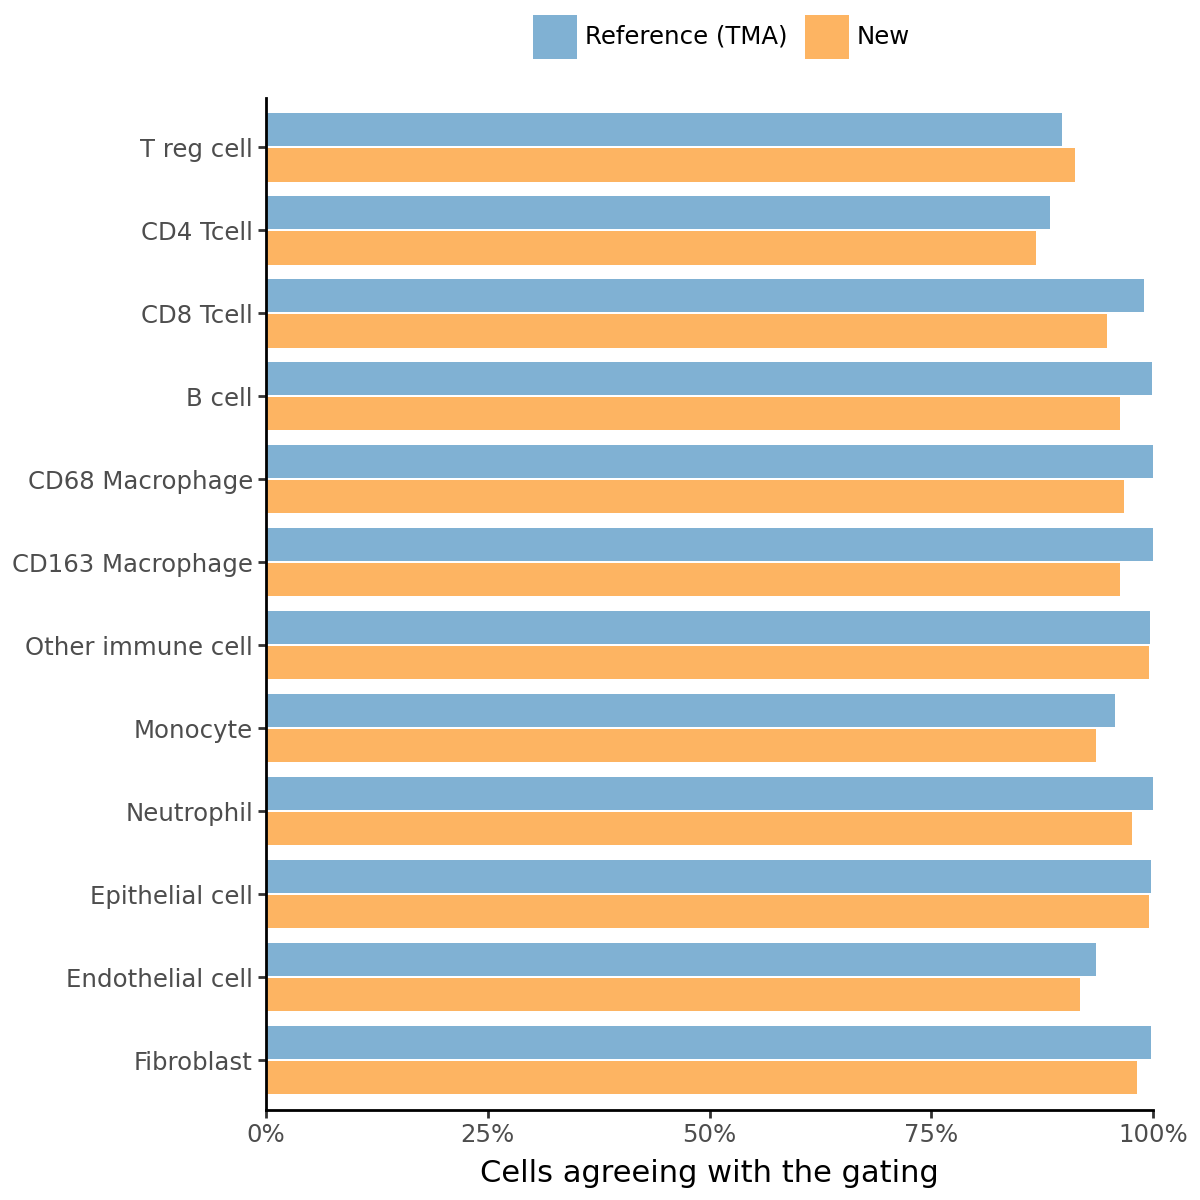

In [31]:
agree_df = pd.concat([
    ref_agree.groupby(ref_labels).mean().rename_axis("cell_type").rename("agreement").reset_index().assign(dataset="Reference (TMA)"),
    new_agree.groupby(new_labels).mean().rename_axis("cell_type").rename("agreement").reset_index().assign(dataset="New"),
])
agree_df["cell_type"] = display_types(agree_df["cell_type"], type_order[::-1])
agree_df["dataset"] = pd.Categorical(agree_df["dataset"], categories=["New", "Reference (TMA)"])

gp = (
    ggplot(agree_df, aes(x="cell_type", y="agreement", fill="dataset"))
    + geom_col(position=position_dodge(width=0.85), width=0.8)
    + coord_flip()
    + scale_fill_manual(values=dataset_colors)
    + guides(fill=guide_legend(reverse=True))
    + scale_y_continuous(labels=percent_labels, limits=(0, 1), expand=(0, 0))
    + theme_classic()
    + theme(legend_position="top", figure_size=(6, 6))
    + labs(x="", y="Cells agreeing with the gating", fill="")
)
ggsave(gp, figure_dir + "gating_agreement.pdf", width=6, height=6, verbose=False)
gp

Fraction of the cells of each transferred label, on the rows, given each gating outcome in the new dataset. The gating outcomes are named after the channels of the new panel.

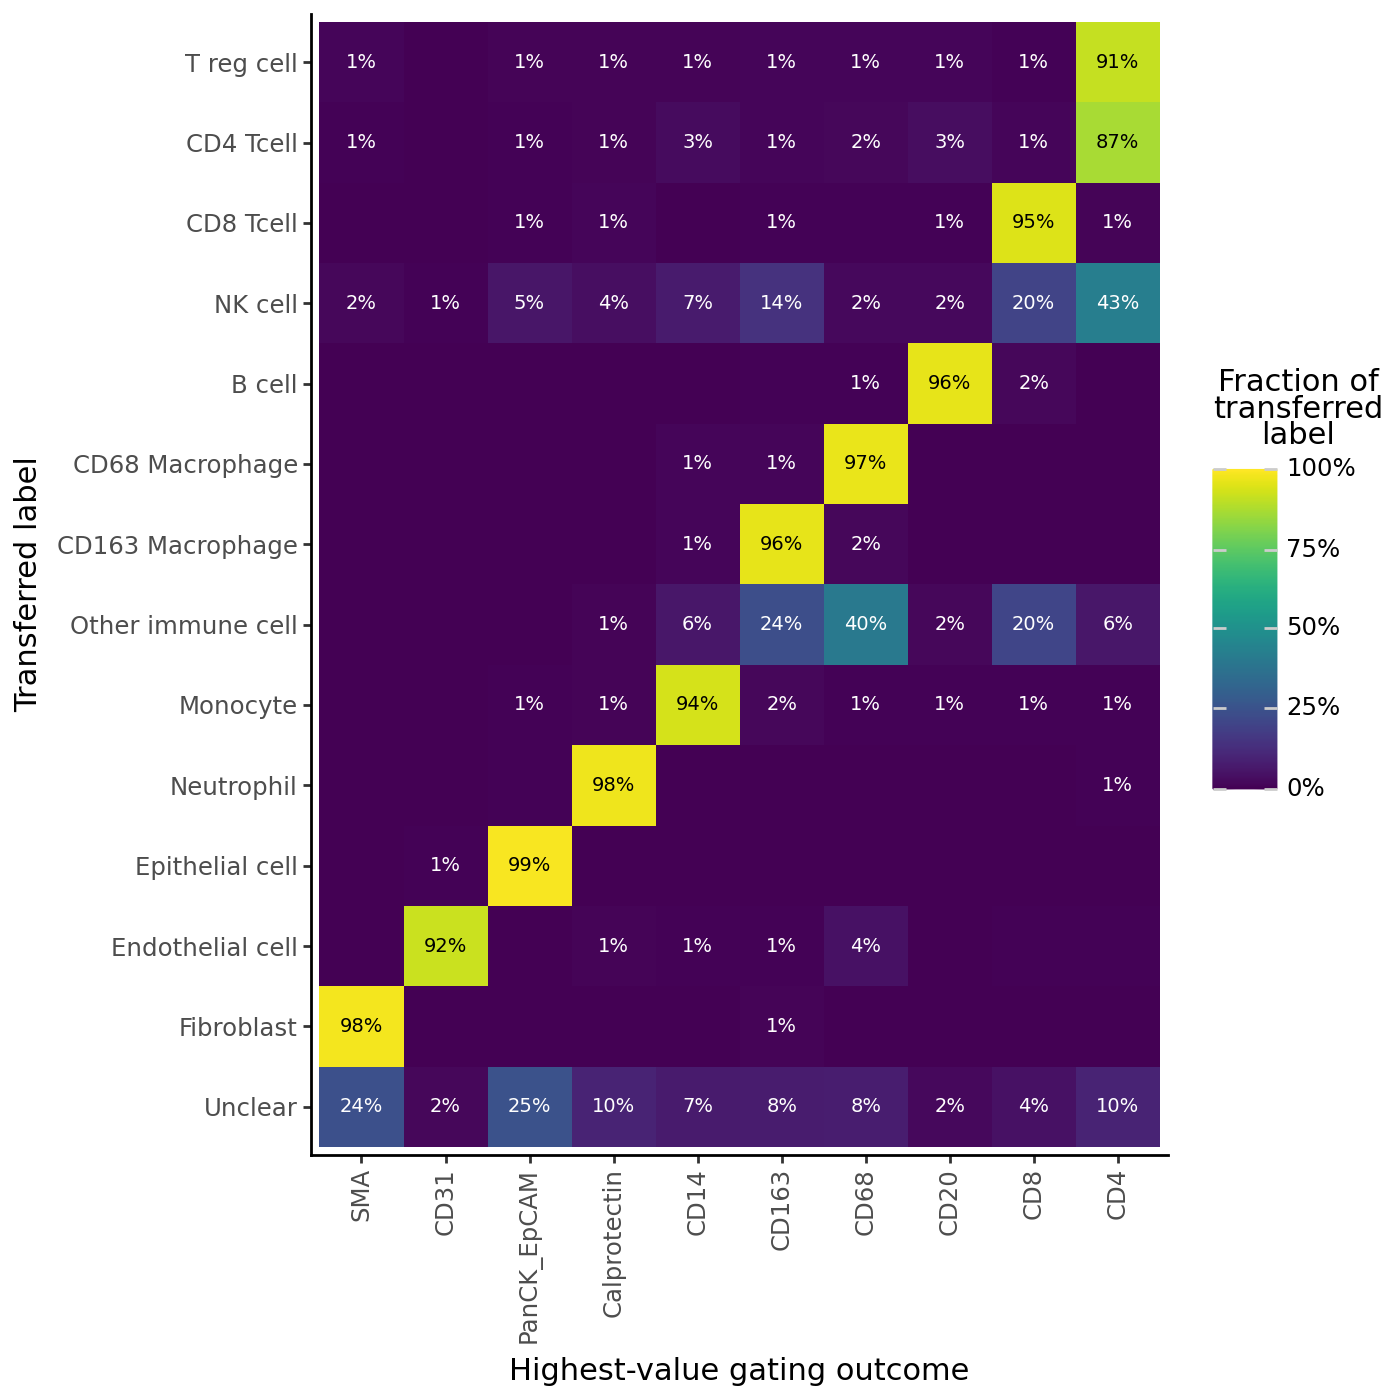

In [32]:
gating_order = [new_channel(m) for m in markers_ordered if m in set(new_gating)]
gating_mat = pd.crosstab(new_labels, new_gating.map(new_channel)).stack().rename("Count").reset_index()
gating_mat.columns = ["Transferred", "Gating", "Count"]
gating_mat["Fraction"] = gating_mat["Count"] / gating_mat.groupby("Transferred")["Count"].transform("sum")
gating_mat["Transferred"] = display_types(gating_mat["Transferred"], type_order[::-1])
gating_mat["Gating"] = pd.Categorical(gating_mat["Gating"], categories=gating_order)
gating_mat = tile_labels(gating_mat)

gp = (
    ggplot(gating_mat, aes(x="Gating", y="Transferred"))
    + geom_tile(aes(fill="Fraction"))
    + geom_text(aes(label="label", color="text_color"), size=7)
    + scale_fill_cmap(cmap_name="viridis", limits=(0, 1), labels=percent_labels)
    + scale_color_identity()
    + theme_classic()
    + theme(axis_text_x=element_text(angle=90), figure_size=(7, 7))
    + labs(x="Highest-value gating outcome", y="Transferred label", fill="Fraction of\ntransferred\nlabel")
)
ggsave(gp, figure_dir + "gating_confusion_matrix.pdf", width=7, height=7, verbose=False)
gp

#### Classifier confidence
Highest class probability of each cell, for held-out reference FOVs and for the new dataset.

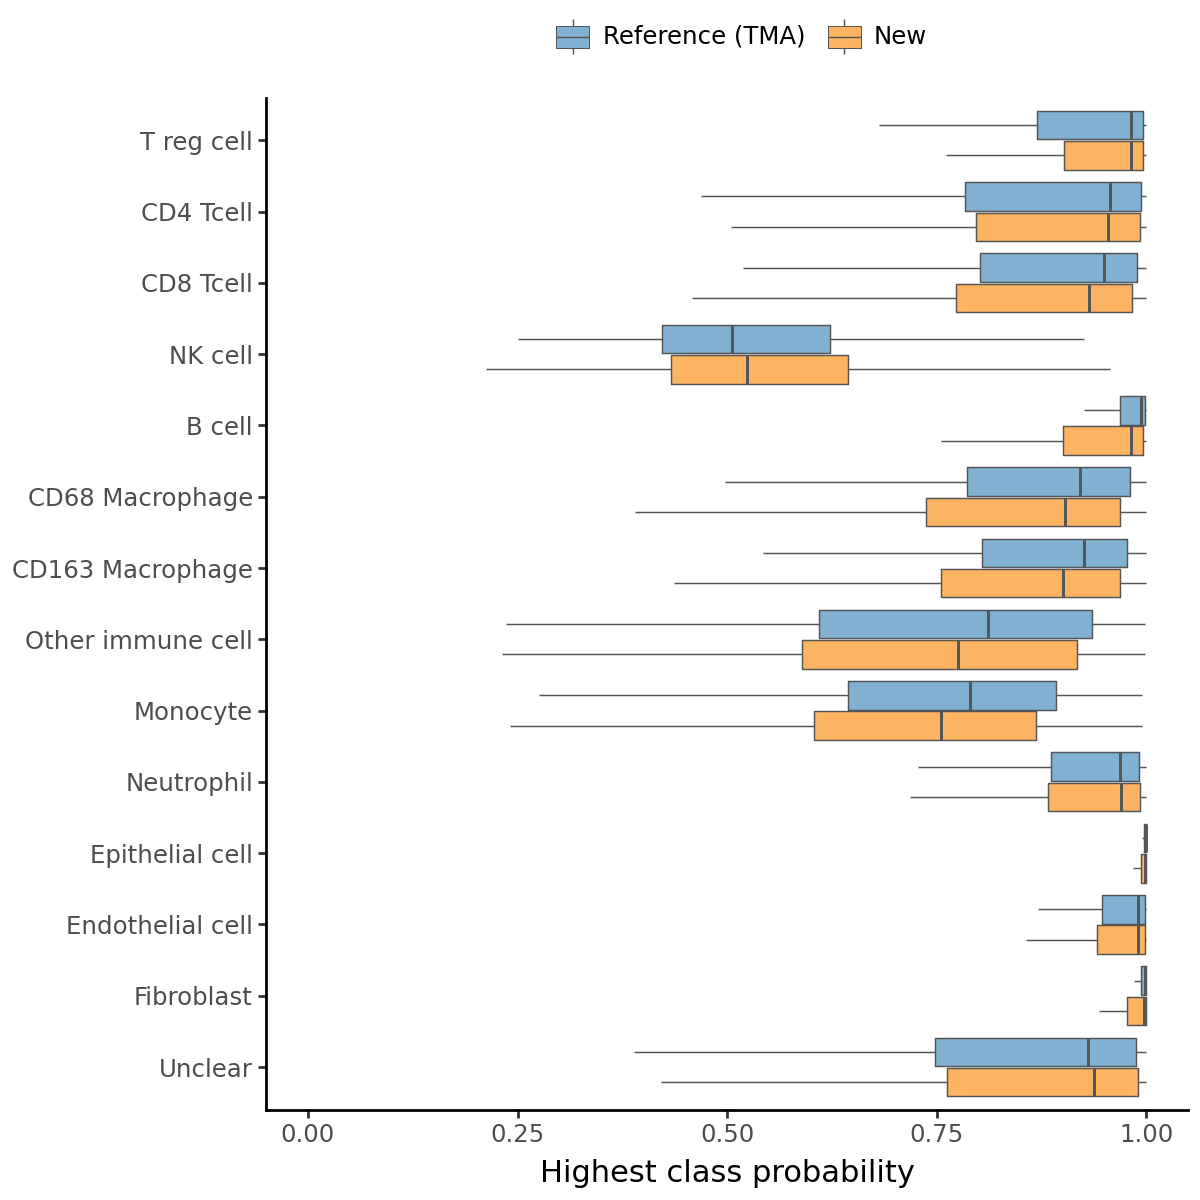

In [33]:
conf_df = pd.concat([
    pd.DataFrame({"cell_type": ref_cv_labels, "confidence": cv_proba.max(axis=1), "dataset": "Reference (TMA)"}),
    pd.DataFrame({"cell_type": new_labels, "confidence": new_confidence, "dataset": "New"}),
])
conf_df["cell_type"] = display_types(conf_df["cell_type"], type_order[::-1])
conf_df["dataset"] = pd.Categorical(conf_df["dataset"], categories=["New", "Reference (TMA)"])

gp = (
    ggplot(conf_df, aes(x="cell_type", y="confidence", fill="dataset"))
    + geom_boxplot(outlier_shape="", color="#555555", size=0.3, position=position_dodge(width=0.85), width=0.8)
    + coord_flip()
    + scale_fill_manual(values=dataset_colors)
    + guides(fill=guide_legend(reverse=True))
    + scale_y_continuous(limits=(0, 1))
    + theme_classic()
    + theme(legend_position="top", figure_size=(6, 6))
    + labs(x="", y="Highest class probability", fill="")
)
ggsave(gp, figure_dir + "classifier_confidence.pdf", width=6, height=6, verbose=False)
gp

### Channels that the classifier never sees
These channels play no part in the annotation, so they test the transferred populations independently. Expected patterns:
* `CD36` is a scavenger receptor of macrophages, monocytes and endothelial cells.
* `Vimentin` is expressed by mesenchymal and immune cells, and by few epithelial cells. It is the only one also measured in the reference.
* `Tox` is a transcription factor of T cells, in particular activated or exhausted ones.
* `COL1A1` is produced by fibroblasts.
* `HNF4a` is a transcription factor of intestinal epithelium, so it should be highest in cancer cells.

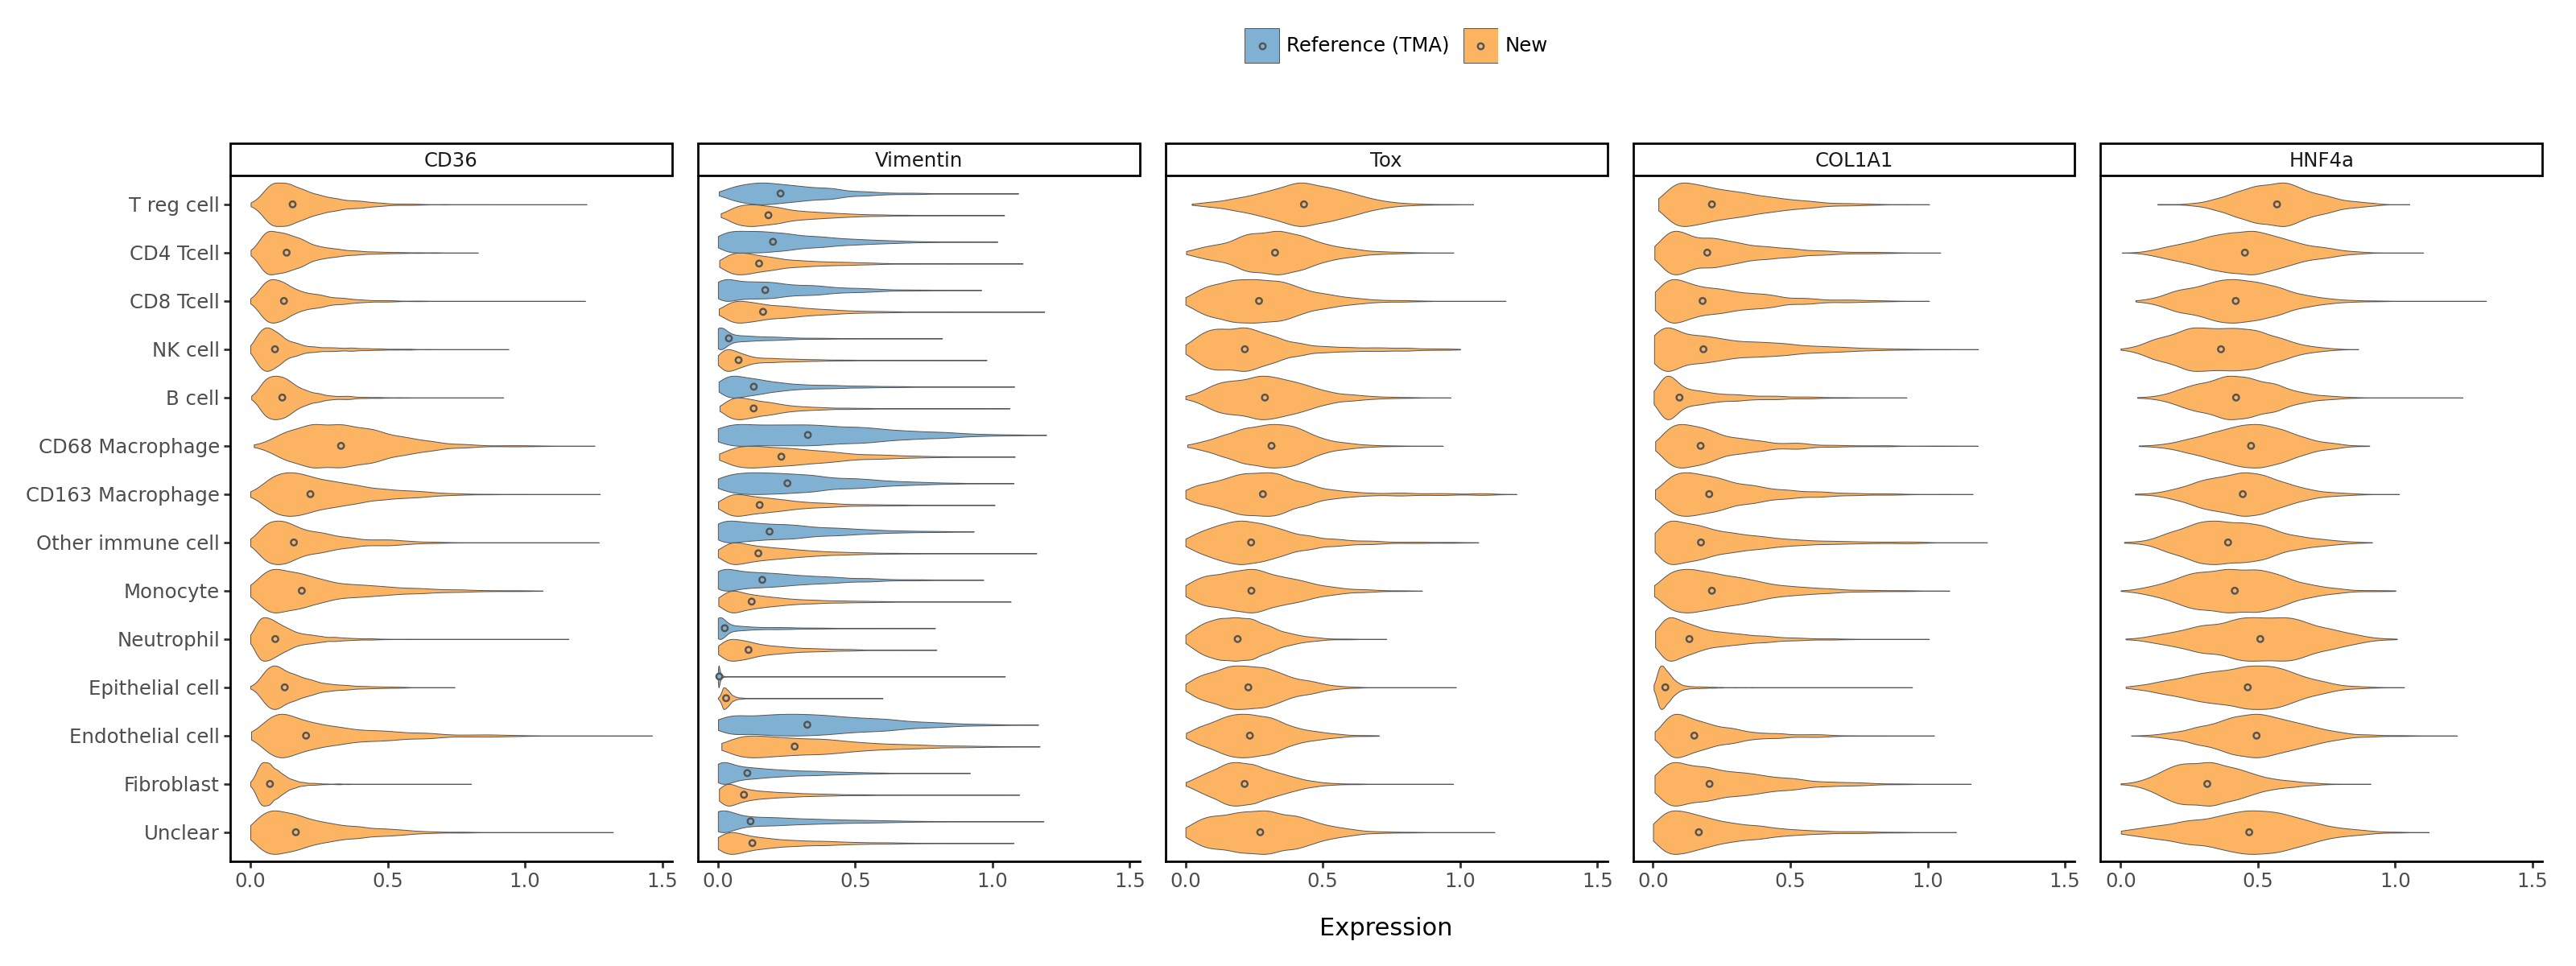

In [34]:
independent_channels = ["CD36", "Vimentin", "Tox", "COL1A1", "HNF4a"]
gp = violins_per_type(sample_per_type(ref.obs[["Vimentin"]], ref_labels),
                      sample_per_type(cells[independent_channels], new_labels),
                      {c: c for c in independent_channels}, ncol=5, figure_size=(16, 6))
ggsave(gp, figure_dir + "violin_independent_channels.pdf", width=16, height=6, verbose=False)
gp

In [35]:
# Median per transferred cell type in the new dataset
cells[independent_channels].groupby(new_labels.values).median().loc[type_order].rename(index=display_name).round(3)

,CD36,Vimentin,Tox,COL1A1,HNF4a
T reg cell,0.156,0.180,0.432,0.216,0.566
CD4 Tcell,0.126,0.147,0.318,0.190,0.445
CD8 Tcell,0.123,0.162,0.270,0.177,0.423
NK cell,0.089,0.075,0.215,0.181,0.364
B cell,0.116,0.130,0.294,0.097,0.426
CD68 Macrophage,0.331,0.235,0.315,0.175,0.478
CD163 Macrophage,0.221,0.153,0.276,0.204,0.438
Other immune cell,0.162,0.149,0.239,0.171,0.401
Monocyte,0.189,0.124,0.241,0.208,0.420
Neutrophil,0.092,0.106,0.192,0.127,0.509


In [36]:
# Vimentin is measured in both datasets: rank correlation of its median per cell type
vimentin_medians = pd.concat({
    "Reference (TMA)": ref.obs["Vimentin"].groupby(ref_labels.values).median(),
    "New": cells["Vimentin"].groupby(new_labels.values).median(),
}, axis=1).loc[type_order]
print(f"Spearman correlation of Vimentin medians across cell types: {vimentin_medians.corr(method='spearman').iloc[0, 1]:.2f}")
vimentin_medians.rename(index=display_name).round(3)

Spearman correlation of Vimentin medians across cell types: 0.94


,Reference (TMA),New
T reg cell,0.228,0.180
CD4 Tcell,0.198,0.147
CD8 Tcell,0.182,0.162
NK cell,0.039,0.075
B cell,0.136,0.130
CD68 Macrophage,0.326,0.235
CD163 Macrophage,0.246,0.153
Other immune cell,0.185,0.149
Monocyte,0.166,0.124
Neutrophil,0.026,0.106


`CD36` is highest in the two macrophage populations, followed by endothelial cells and monocytes. `Vimentin` is lowest in cancer cells and highest in endothelial cells and CD68 macrophages, and it ranks the cell types in nearly the same order as in the reference. `Tox` is highest in regulatory T cells, followed by CD4 T cells and CD68 macrophages, so it supports the regulatory T cells more than T cells in general. These channels support the transferred labels.

`COL1A1` is lowest in cancer cells, but CAFs do not stand out from immune cells. `HNF4a` is about as high in every population as in cancer cells. Neither channel separates the populations, which points to the staining of these two channels rather than to the labels, but they give no support either.

### Spatial organisation
The classifier never sees cell positions. Cells of one type tend to sit together in tissue, for example epithelium, stroma or lymphoid aggregates, while a wrong label would scatter cells at random among other types. For each cell, the 10 nearest cells of the same FOV are its neighbours.

The first plot shows, for each cell type, the fraction of neighbours with the same label, divided by the fraction expected if labels were placed at random within each FOV, on a log2 scale. 0 means no more same-type neighbours than chance. Shuffling the new labels within each FOV is a control that should give 0.

Spillover of signal between touching cells can also make neighbours look alike, so this check supports the labels but cannot rule out such artefacts on its own.

In [37]:
def neighbour_indices(obs, k=10):
    """Indices of the k nearest cells of the same FOV, for each cell"""
    fovs = obs["fov"].astype(str).values
    xy = obs[["centroid-0", "centroid-1"]].values
    neighbours = np.zeros((len(obs), k), dtype=int)
    for fov in np.unique(fovs):
        idx = np.where(fovs == fov)[0]
        knn = NearestNeighbors(n_neighbors=k + 1).fit(xy[idx]).kneighbors(xy[idx], return_distance=False)
        neighbours[idx] = idx[knn[:, 1:]]
    return neighbours

def same_type_enrichment(labels, neighbours, fovs):
    """log2 ratio of observed to expected fraction of same-type neighbours, per cell type"""
    labels = np.asarray(labels)
    observed = (labels[neighbours] == labels[:, None]).mean(axis=1)
    # Expected under random labels within the FOV: share of the other cells of the FOV with the same label
    counts = pd.crosstab(fovs, labels)
    fov_size = counts.sum(axis=1)
    expected = (counts.values[counts.index.get_indexer(fovs), counts.columns.get_indexer(labels)] - 1) / (fov_size.loc[fovs].values - 1)
    per_type = pd.DataFrame({"cell_type": labels, "observed": observed, "expected": expected}).groupby("cell_type").mean()
    return np.log2(per_type["observed"] / per_type["expected"])

def shuffle_within_fov(labels, fovs, seed):
    rng = np.random.default_rng(seed)
    shuffled = np.asarray(labels).copy()
    for fov in np.unique(fovs):
        idx = np.where(fovs == fov)[0]
        shuffled[idx] = rng.permutation(shuffled[idx])
    return shuffled

ref_fovs, new_fovs = ref.obs["fov"].astype(str).values, cells["fov"].astype(str).values
ref_neighbours = neighbour_indices(ref.obs)
new_neighbours = neighbour_indices(cells)

enrichment = pd.concat({
    "Reference (TMA)": same_type_enrichment(ref_labels, ref_neighbours, ref_fovs),
    "New": same_type_enrichment(new_labels, new_neighbours, new_fovs),
    "New, shuffled labels": same_type_enrichment(shuffle_within_fov(new_labels, new_fovs, seed), new_neighbours, new_fovs),
}, axis=1).loc[type_order]
enrichment.rename(index=display_name).round(2)

,Reference (TMA),New,"New, shuffled labels"
cell_type,,,
T reg cell,1.78,1.74,-0.05
CD4 Tcell,1.19,1.27,-0.00
CD8 Tcell,1.65,1.49,-0.02
NK cell,1.53,2.02,-0.14
B cell,0.57,2.21,0.02
CD68 Macrophage,1.44,1.85,0.03
CD163 Macrophage,1.21,1.28,0.01
Other immune cell,1.25,1.11,-0.01
Monocyte,1.03,1.26,0.01


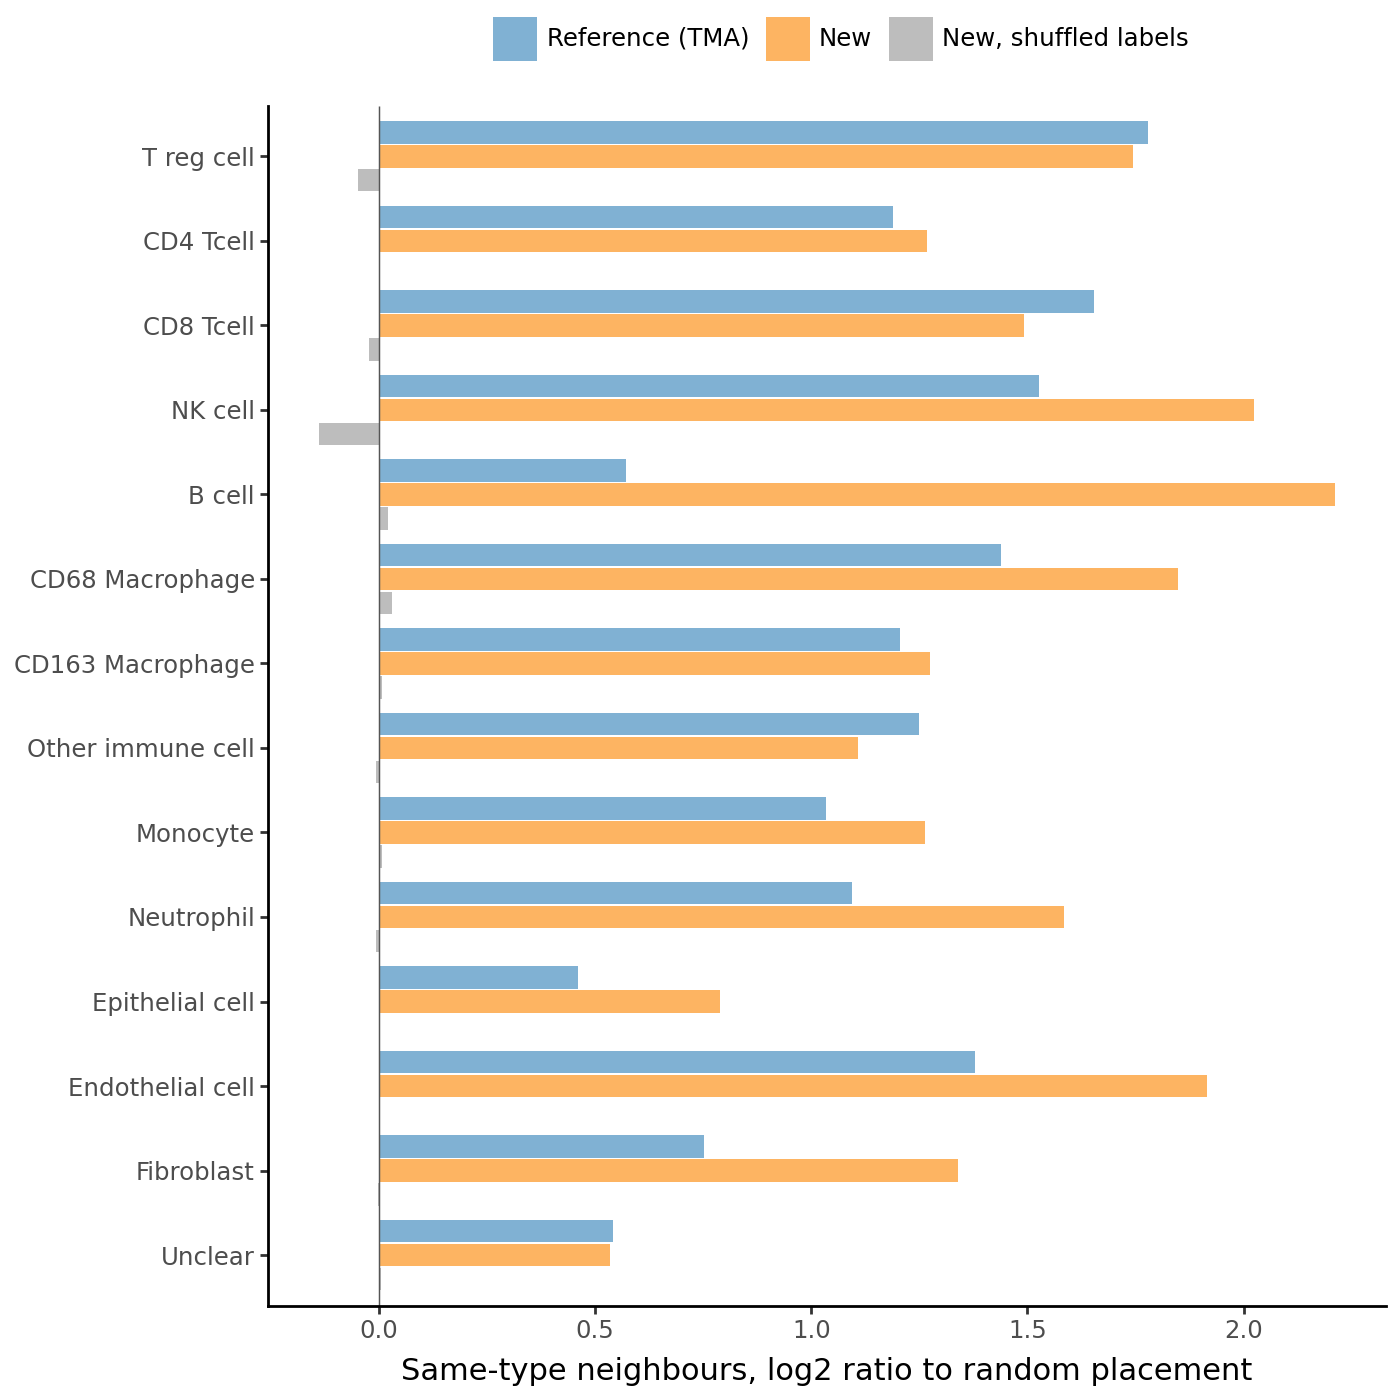

In [38]:
enrich_df = enrichment.melt(ignore_index=False, var_name="dataset", value_name="log2_enrichment").rename_axis("cell_type").reset_index()
enrich_df["cell_type"] = display_types(enrich_df["cell_type"], type_order[::-1])
enrich_df["dataset"] = pd.Categorical(enrich_df["dataset"], categories=["New, shuffled labels", "New", "Reference (TMA)"])

gp = (
    ggplot(enrich_df, aes(x="cell_type", y="log2_enrichment", fill="dataset"))
    + geom_col(position=position_dodge(width=0.85), width=0.8)
    + geom_hline(yintercept=0, color="#555555", size=0.3)
    + coord_flip()
    + scale_fill_manual(values=dataset_colors)
    + guides(fill=guide_legend(reverse=True))
    + theme_classic()
    + theme(legend_position="top", figure_size=(7, 7))
    + labs(x="", y="Same-type neighbours, log2 ratio to random placement", fill="")
)
ggsave(gp, figure_dir + "spatial_same_type_enrichment.pdf", width=7, height=7, verbose=False)
gp

Every transferred population has more same-type neighbours than random placement, as in the reference, and shuffled labels give values close to 0. B cells cluster much more strongly in the new dataset than in the reference, which fits lymphoid aggregates at the invasive margin, a region the TMA cores rarely cover.

The second check compares which cell types surround each population. For each cell type, the neighbourhood profile is the log2 ratio of each type among its neighbours to that type's share of the FOV. The heatmap shows the Spearman correlation between the profile of each reference type and the profile of each transferred type. Both cell types of a pair are left out of the correlation, so a population's preference for its own type cannot drive it.

The profiles mostly separate epithelial, stromal and immune neighbourhoods, so many pairs of immune types correlate well. A transferred population should still correlate best with its own reference type, on the diagonal.

In [39]:
def neighbourhood_profiles(labels, neighbours, fovs, types):
    """log2 ratio of each type among the neighbours of each type, to that type's share of the FOV"""
    labels = np.asarray(labels)
    onehot = (labels[:, None] == np.array(types)[None, :]).astype(float)
    neighbour_share = onehot[neighbours].mean(axis=1)
    fov_share = pd.DataFrame(onehot, columns=types).groupby(fovs).transform("mean").values
    observed = pd.DataFrame(neighbour_share, columns=types).groupby(labels).mean()
    expected = pd.DataFrame(fov_share, columns=types).groupby(labels).mean()
    return np.log2(observed / expected).loc[types]

ref_neighbourhoods = neighbourhood_profiles(ref_labels, ref_neighbours, ref_fovs, type_order)
new_neighbourhoods = neighbourhood_profiles(new_labels, new_neighbours, new_fovs, type_order)

neighbourhood_corr = pd.DataFrame(index=type_order, columns=type_order, dtype=float)
for ref_type in type_order:
    for new_type in type_order:
        others = [t for t in type_order if t not in (ref_type, new_type)]
        neighbourhood_corr.loc[ref_type, new_type] = spearmanr(
            ref_neighbourhoods.loc[ref_type, others], new_neighbourhoods.loc[new_type, others])[0]

best_match = pd.DataFrame({
    "own type": np.diag(neighbourhood_corr),
    "best match": neighbourhood_corr.idxmax(axis=1),
    "best correlation": neighbourhood_corr.max(axis=1),
    "median of other types": [neighbourhood_corr.loc[t].drop(t).median() for t in type_order],
}, index=type_order)
print(f"Own type is the best match for {np.sum(best_match['best match'] == best_match.index)} of {len(type_order)} cell types")
best_match.assign(**{"best match": best_match["best match"].map(display_name)}).rename(index=display_name).round(2)

Own type is the best match for 6 of 14 cell types


,own type,best match,best correlation,median of other types
T reg cell,0.76,B cell,0.86,0.63
CD4 Tcell,0.82,B cell,0.91,0.67
CD8 Tcell,0.82,B cell,0.88,0.73
NK cell,0.83,CD4 Tcell,0.90,0.44
B cell,0.87,T reg cell,0.98,0.49
CD68 Macrophage,0.96,CD68 Macrophage,0.96,0.63
CD163 Macrophage,0.72,CD68 Macrophage,0.89,0.57
Other immune cell,0.87,Other immune cell,0.87,0.58
Monocyte,0.80,CD68 Macrophage,0.94,0.54
Neutrophil,0.71,Endothelial cell,0.77,0.54


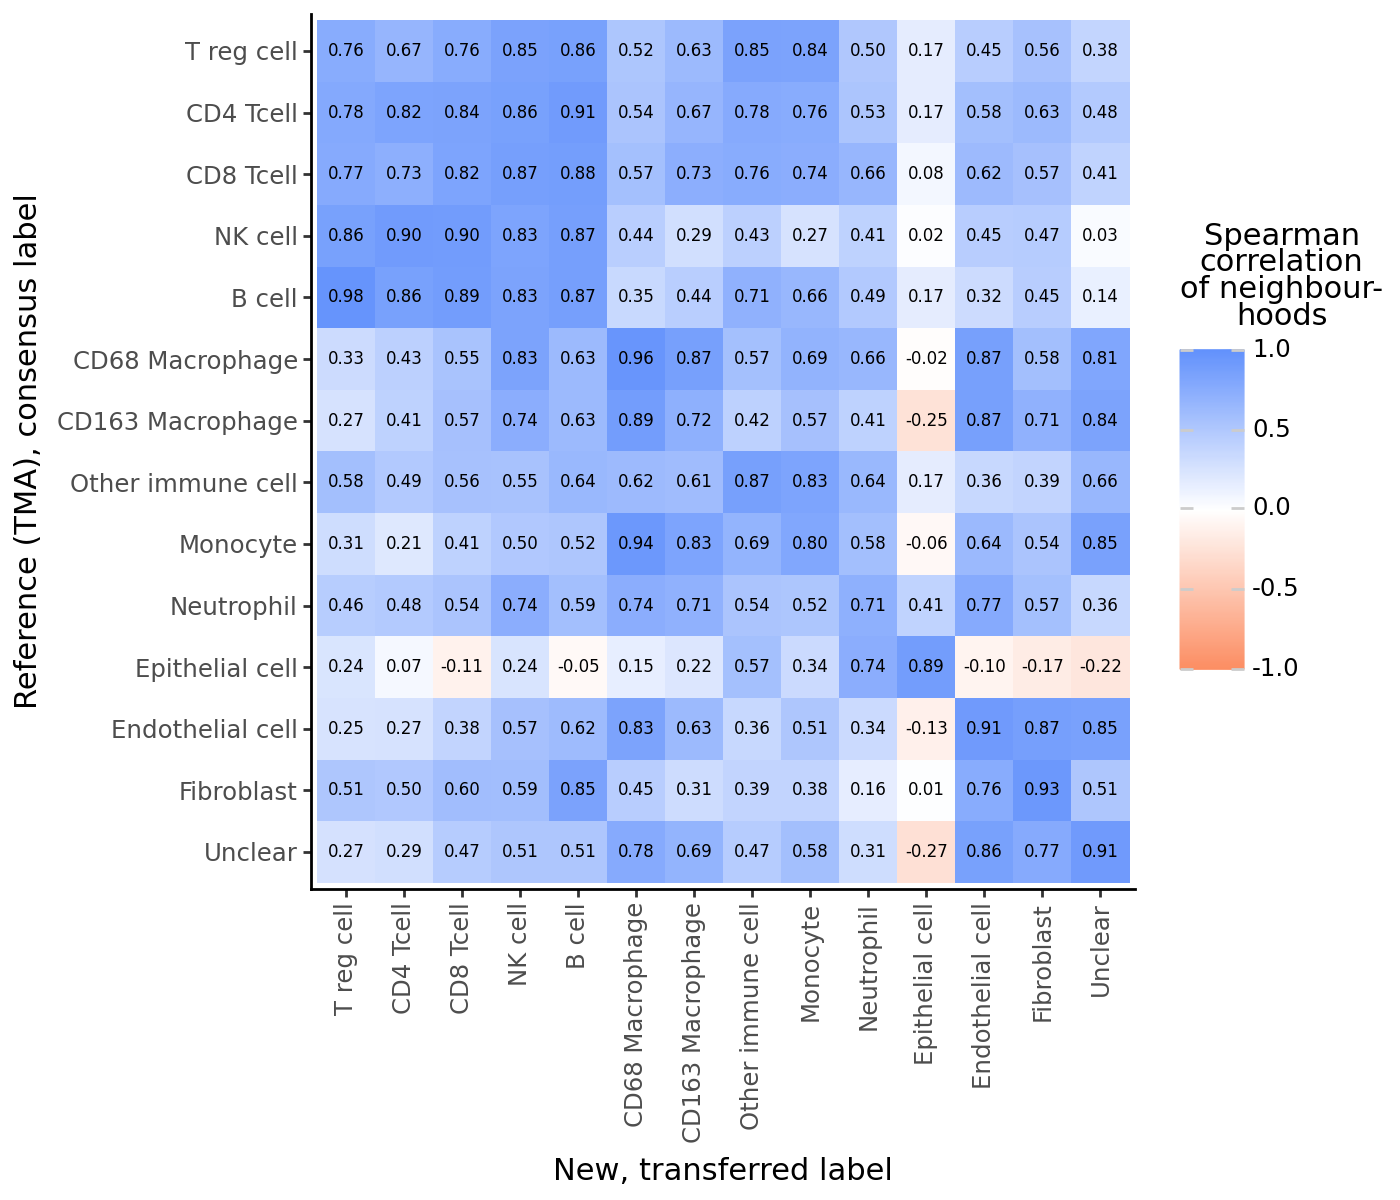

In [40]:
ncorr_df = neighbourhood_corr.stack().rename("Correlation").reset_index()
ncorr_df.columns = ["Reference", "New", "Correlation"]
ncorr_df["Reference"] = display_types(ncorr_df["Reference"], type_order[::-1])
ncorr_df["New"] = display_types(ncorr_df["New"], type_order)
ncorr_df["label"] = ncorr_df["Correlation"].map(lambda r: f"{r:.2f}")

gp = (
    ggplot(ncorr_df, aes(x="New", y="Reference"))
    + geom_tile(aes(fill="Correlation"))
    + geom_text(aes(label="label"), size=6)
    + scale_fill_correlation()
    + theme_classic()
    + theme(axis_text_x=element_text(angle=90), figure_size=(7, 6))
    + labs(x="New, transferred label", y="Reference (TMA), consensus label", fill="Spearman\ncorrelation\nof neighbour-\nhoods")
)
ggsave(gp, figure_dir + "spatial_neighbourhood_correlation.pdf", width=7, height=6, verbose=False)
gp

For 6 of the 14 cell types, the transferred population is the best match for the neighbourhood of its own reference type: cancer cells, CAFs, endothelial cells, CD68 macrophages, `Other_immune_cell` and `Unclear`. Cancer cells match their own type at 0.89, against a median of 0.15 for the other types.

The lymphocytes do not separate. Reference T cells and NK cells are best matched by transferred B cells or CD4 T cells, and reference B cells by transferred regulatory T cells. The new FOVs include the invasive margin, where lymphocytes of several types probably gather in the same aggregates, so their neighbourhoods look alike. Reference CD163 macrophages and monocytes are best matched by transferred CD68 macrophages, and neutrophils by endothelial cells. This check separates tissue compartments, but not immune subtypes.

### Do the replacement channels mark the same cells?
The main classifier uses `Calprotectin` as `MPO` and `PanCK_EpCAM` as `PanCK`, so it assumes what this section tests. A second classifier trains on the 11 channels that both panels measure, without `MPO` and `PanCK`. If `Calprotectin` and `PanCK_EpCAM` mark the same cells as `MPO` and `PanCK`, the cells this classifier calls neutrophils should have high `Calprotectin`, and its cancer cells high `PanCK_EpCAM`.

The AUROC is the probability that a cell called a neutrophil has more `Calprotectin` than a cell given another label. 1 means perfect separation and 0.5 means none. The same AUROC for `MPO` and `PanCK` in the reference consensus shows what a good annotation reaches.

In [41]:
strict_channels = [c for c in shared_channels if c not in new_to_ref.values()]
strict_model = XGBClassifier(**xgb_params).fit(ref_X[strict_channels], y)
strict_labels = encoder.inverse_transform(strict_model.predict(new_X[strict_channels]))

replacement_check = []
for new_ch, ref_ch, cell_type in [("Calprotectin", "MPO", "Neutrophil"), ("PanCK_EpCAM", "PanCK", "Cancer_cell")]:
    replacement_check.append({
        "cell type": display_name(cell_type),
        "new channel": new_ch,
        "new: fraction of cells": np.mean(strict_labels == cell_type),
        "new: AUROC": roc_auc_score(strict_labels == cell_type, new_panel_X[new_ch]),
        "reference channel": ref_ch,
        "reference: fraction of cells": np.mean(ref_labels == cell_type),
        "reference: AUROC": roc_auc_score(ref_labels == cell_type, ref_X[ref_ch]),
    })
pd.DataFrame(replacement_check).set_index("cell type").round(3)

,new channel,new: fraction of cells,new: AUROC,reference channel,reference: fraction of cells,reference: AUROC
cell type,,,,,,
Neutrophil,Calprotectin,0.039,0.875,MPO,0.033,0.984
Epithelial cell,PanCK_EpCAM,0.256,0.799,PanCK,0.453,0.869


Without `PanCK_EpCAM`, cancer cells are mostly cells low in every other lineage channel, so this classifier calls far fewer cells cancer cells than the main one. It only serves this check.

### Can NK cells be found without `CD7`?
The reference is split into 200 k-means clusters twice. The first clustering uses all 15 reference lineage channels. The second leaves out `CD7` and `HLADRa`, which the new panel lacks. The table shows the five highest fractions of NK cells in a cluster. If NK cells form no cluster of their own without `CD7`, no method can recover them from the new panel.

In [42]:
full_ref_X = pd.DataFrame(ref.X, columns=ref.var_names, index=ref.obs_names)
nk_cell = (ref.obs["annotation_consensus"] == "NK_cell").values

def top_nk_fractions(X, n=5):
    clusters = KMeans(n_clusters=200, n_init=3, random_state=seed).fit_predict(X)
    return pd.Series(nk_cell).groupby(clusters).mean().sort_values(ascending=False).values[:n]

pd.DataFrame({
    "with CD7 and HLADRa": top_nk_fractions(full_ref_X),
    "without CD7 and HLADRa": top_nk_fractions(full_ref_X.drop(columns=["CD7", "HLADRa"])),
}, index=[f"cluster rank {i + 1}" for i in range(5)]).round(2)

,with CD7 and HLADRa,without CD7 and HLADRa
cluster rank 1,0.48,0.15
cluster rank 2,0.40,0.14
cluster rank 3,0.22,0.10
cluster rank 4,0.22,0.10
cluster rank 5,0.15,0.08


### Does a confidence cutoff make the populations more coherent?
A cell whose highest class probability is below a cutoff could be set to `Unclear` instead of its predicted type. This section repeats the checks above for several cutoffs. The independent channels are scored as AUROCs among labelled cells: `CD36` for macrophages against the other types, `Vimentin` for the other types against cancer cells, and `Tox` for regulatory T cells against the other types. The same cutoffs are applied to the held-out reference predictions, where the F1 score shows what each cutoff costs against the consensus labels.

In [43]:
cutoffs = [0, 0.5, 0.6, 0.7, 0.8, 0.9]
labelled_types = [t for t in type_order if t != "Unclear"]
ref_cv_confidence = pd.Series(cv_proba.max(axis=1), index=ref_cv_labels.index)

def with_cutoff(labels, confidence, cutoff):
    return labels.where(confidence >= cutoff, "Unclear")

cutoff_checks, kept_fraction, cv_f1 = [], {}, {}
for cutoff in cutoffs:
    labels = with_cutoff(new_labels, new_confidence, cutoff)
    labelled = (labels != "Unclear").values
    profiles = type_profiles(new_X, labels)
    cutoff_checks.append({
        "cutoff": cutoff,
        "cells labelled": labelled.mean(),
        "gating agreement": rule_agreement(labels, new_gating).mean(),
        "marker profile SCC, median": np.median([spearmanr(ref_profiles.loc[t], profiles.loc[t])[0] for t in labelled_types]),
        "same-type log2 enrichment, median": same_type_enrichment(labels, new_neighbours, new_fovs).drop("Unclear").median(),
        "CD36 AUROC, macrophages": roc_auc_score(labels.isin(["CD68_Macrophage", "CD163_Macrophage"]).values[labelled], cells["CD36"].values[labelled]),
        "Vimentin AUROC, not epithelial cells": roc_auc_score((labels != "Cancer_cell").values[labelled], cells["Vimentin"].values[labelled]),
        "Tox AUROC, regulatory T cells": roc_auc_score((labels == "T_reg_cell").values[labelled], cells["Tox"].values[labelled]),
    })
    kept_fraction[cutoff] = (new_confidence >= cutoff).groupby(new_labels).mean()
    ref_cv_cut = with_cutoff(ref_cv_labels, ref_cv_confidence, cutoff)
    cv_f1[cutoff] = pd.Series(f1_score(ref_labels, ref_cv_cut, labels=labelled_types, average=None), index=labelled_types)
pd.DataFrame(cutoff_checks).set_index("cutoff").T.round(3)

cutoff,0.0,0.5,0.6,0.7,0.8,0.9
cells labelled,0.781,0.760,0.729,0.695,0.653,0.589
gating agreement,0.970,0.975,0.981,0.986,0.991,0.995
"marker profile SCC, median",0.934,0.940,0.934,0.934,0.934,0.945
"same-type log2 enrichment, median",1.493,1.519,1.538,1.575,1.632,1.801
"CD36 AUROC, macrophages",0.757,0.757,0.758,0.761,0.767,0.786
"Vimentin AUROC, not epithelial cells",0.888,0.889,0.889,0.890,0.890,0.891
"Tox AUROC, regulatory T cells",0.811,0.814,0.817,0.819,0.825,0.833


Fraction of the cells of each transferred type that keep their label, per cutoff:

In [44]:
pd.DataFrame(kept_fraction).loc[labelled_types].rename(index=display_name).round(2)

,0.0,0.5,0.6,0.7,0.8,0.9
T reg cell,1.0,0.98,0.94,0.90,0.84,0.75
CD4 Tcell,1.0,0.95,0.89,0.82,0.75,0.63
CD8 Tcell,1.0,0.95,0.89,0.81,0.72,0.58
NK cell,1.0,0.56,0.32,0.18,0.07,0.02
B cell,1.0,0.97,0.93,0.89,0.84,0.75
CD68 Macrophage,1.0,0.94,0.87,0.79,0.68,0.51
CD163 Macrophage,1.0,0.96,0.89,0.81,0.69,0.50
Other immune cell,1.0,0.87,0.74,0.60,0.46,0.29
Monocyte,1.0,0.89,0.76,0.60,0.41,0.17
Neutrophil,1.0,0.98,0.94,0.90,0.83,0.72


F1 score of each type on held-out reference FOVs, per cutoff:

In [45]:
pd.DataFrame(cv_f1).rename(index=display_name).round(3)

,0.0,0.5,0.6,0.7,0.8,0.9
T reg cell,0.898,0.895,0.888,0.876,0.854,0.813
CD4 Tcell,0.897,0.896,0.890,0.871,0.840,0.776
CD8 Tcell,0.901,0.900,0.892,0.879,0.846,0.772
NK cell,0.221,0.155,0.099,0.052,0.020,0.004
B cell,0.946,0.945,0.944,0.940,0.930,0.912
CD68 Macrophage,0.906,0.907,0.900,0.878,0.832,0.724
CD163 Macrophage,0.912,0.911,0.903,0.884,0.846,0.739
Other immune cell,0.741,0.732,0.702,0.655,0.578,0.435
Monocyte,0.839,0.832,0.802,0.742,0.620,0.376
Neutrophil,0.946,0.944,0.941,0.928,0.902,0.841


Raising the cutoff improves most checks, but slowly. At a cutoff of 0.7, 69% of cells keep a label instead of 78%. Gating agreement rises from 97.0% to 98.6% and the median same-type enrichment from 1.49 to 1.58. The AUROCs of the independent channels change by at most 0.01, and the marker profile correlations barely change.

The removed cells are not spread evenly across types. At 0.7, cancer cells and CAFs keep 96 to 98% of their labels, monocytes and `Other_immune_cell` 60%, and NK cells 18%. A cutoff therefore changes the cell type mix, mostly among immune cells. On the reference, from a cutoff of 0.6, the F1 score falls for every type except cancer cells, because recall drops faster than precision rises.

The reference consensus labels had no such cutoff, so a cutoff on the new dataset alone would make the two annotations less comparable. The notebook applies no cutoff. An analysis that needs cleaner populations can filter on the exported `annotation_confidence`.

## Coarse classes
### Grouped fine predictions or direct training
Two ways to obtain the classes of `PrepareMuData.ipynb`:
* Grouped: predict the fine consensus labels, then merge them into the coarse classes.
* Direct: train the classifier on the coarse classes.

Both are scored on the same held-out FOVs of the reference. These cells have real `MPO` and `PanCK` values, so the scores do not test `Calprotectin` or `PanCK_EpCAM`.

The notebook keeps the grouped approach: the direct classifier reaches no higher F1 for any coarse class, and grouping also keeps the fine labels.

In [46]:
ref_coarse = ref_labels.replace(type_to_group)
coarse_encoder = LabelEncoder().fit(ref_coarse)

cv_coarse_proba = cross_validate(ref_X, ref_coarse)
ref_cv_coarse = pd.Series(coarse_encoder.inverse_transform(cv_coarse_proba.argmax(axis=1)), index=ref_labels.index)

coarse_reports = {
    "Grouped": classification_report(ref_coarse, ref_cv_labels.replace(type_to_group), output_dict=True),
    "Direct": classification_report(ref_coarse, ref_cv_coarse, output_dict=True),
}
coarse_cv = pd.concat({approach: pd.DataFrame(report).T[["precision", "recall", "f1-score"]]
                       for approach, report in coarse_reports.items()}, axis=1)
coarse_cv.loc[coarse_ordered + ["macro avg", "weighted avg"]].rename(index=display_name).round(4)

Grouped                     Direct                 
                     precision  recall f1-score precision  recall f1-score
CD4 lymphocyte          0.8892  0.9145   0.9017    0.8883  0.9151   0.9015
Cytotoxic lymphocyte    0.8576  0.6567   0.7438    0.8515  0.6577   0.7422
Macrophage              0.8947  0.9445   0.9189    0.8936  0.9427   0.9175
Monocyte                0.8042  0.8766   0.8389    0.8015  0.8738   0.8361
Other immune cell       0.8859  0.8578   0.8716    0.8837  0.8516   0.8674
Epithelial cell         0.9898  0.9939   0.9919    0.9896  0.9939   0.9917
Endothelial cell        0.9526  0.9670   0.9598    0.9520  0.9668   0.9594
Fibroblast              0.9847  0.9905   0.9876    0.9845  0.9906   0.9875
Unclear                 0.8905  0.8656   0.8779    0.8902  0.8652   0.8775
macro avg               0.9055  0.8963   0.8991    0.9039  0.8953   0.8979
weighted avg            0.9458  0.9459   0.9454    0.9451  0.9452   0.9447

### Coarse classes on the new dataset
The new cells have no labels, so this only compares the two approaches with each other: how many cells get the same coarse class, and the class proportions of both. Only the grouped classes are exported.

In [47]:
coarse_model = XGBClassifier(**xgb_params).fit(ref_X, coarse_encoder.transform(ref_coarse))
new_coarse = pd.Series(coarse_encoder.inverse_transform(coarse_model.predict(new_X)), index=new_X.index)
new_grouped = new_labels.replace(type_to_group)

print(f"Cells with the same coarse class in both approaches: {np.mean(new_grouped == new_coarse):.1%}")
pd.crosstab(new_grouped.rename("Grouped"), new_coarse.rename("Direct")).loc[coarse_ordered, coarse_ordered].rename(index=display_name, columns=display_name)

Cells with the same coarse class in both approaches: 97.3%


Direct,CD4 lymphocyte,Cytotoxic lymphocyte,Macrophage,Monocyte,Other immune cell,Epithelial cell,Endothelial cell,Fibroblast,Unclear
Grouped,,,,,,,,,
CD4 lymphocyte,38400,244,13,35,604,1,0,0,404
Cytotoxic lymphocyte,314,19211,2,103,641,0,4,10,307
Macrophage,9,6,36274,239,191,0,3,2,873
Monocyte,56,184,260,32603,721,0,3,0,765
Other immune cell,805,821,249,465,62429,8,7,22,1706
Epithelial cell,0,3,0,0,2,232003,10,3,719
Endothelial cell,0,1,2,1,2,4,37568,0,408
Fibroblast,0,1,0,0,5,0,0,63510,406
Unclear,520,570,1088,921,2116,818,554,389,142423


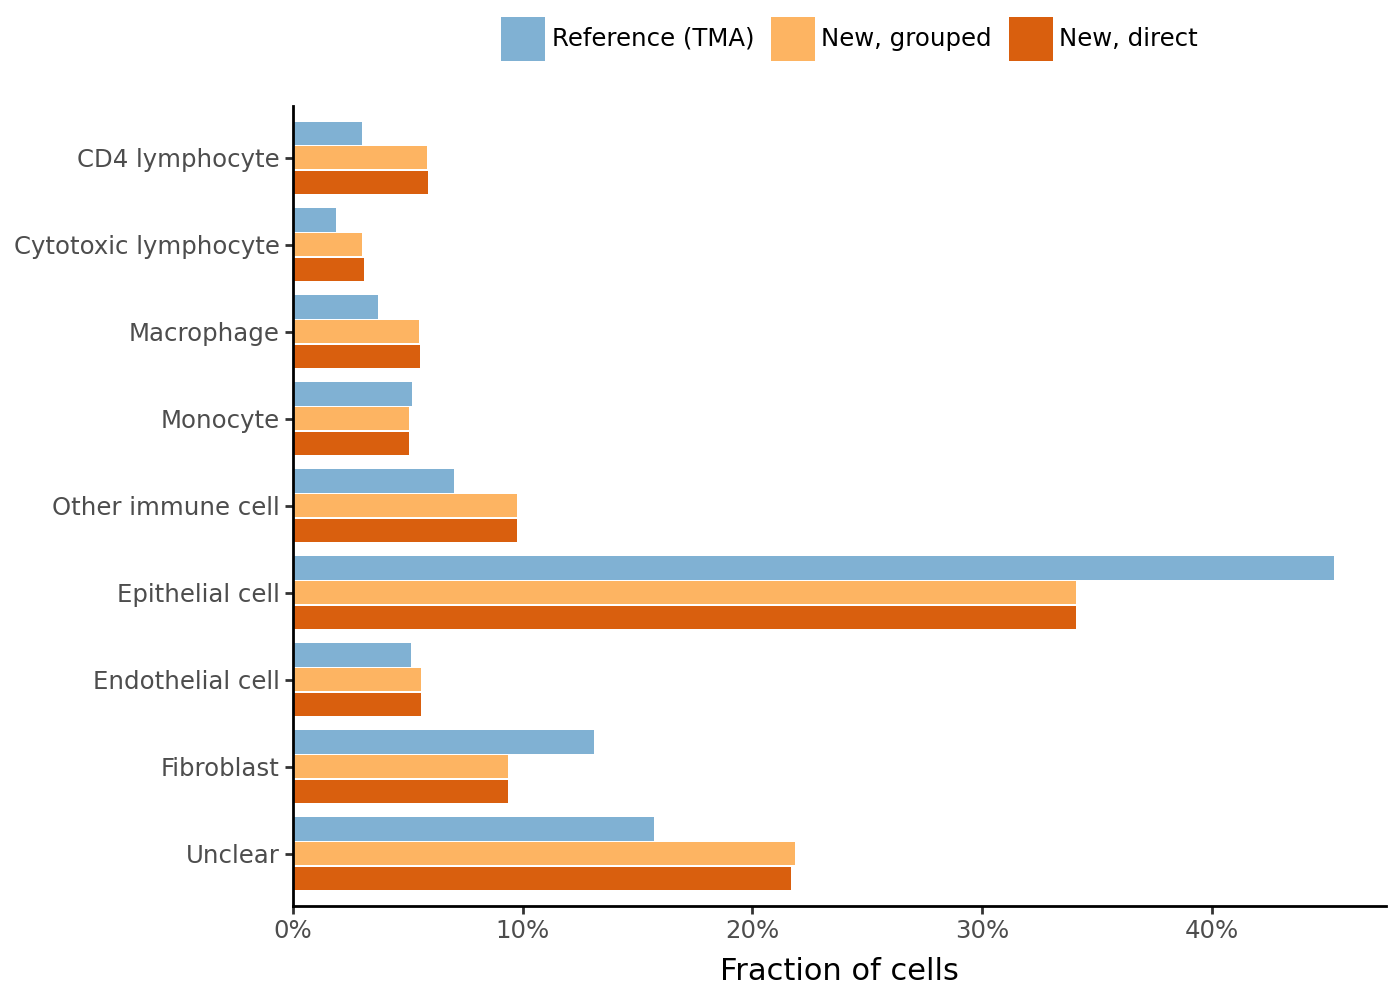

In [48]:
coarse_colors = {"Reference (TMA)": dataset_colors["Reference (TMA)"], "New, grouped": dataset_colors["New"], "New, direct": "#d95f0e"}
coarse_prop = pd.concat([
    type_proportions(ref_coarse, "Reference (TMA)"),
    type_proportions(new_grouped, "New, grouped"),
    type_proportions(new_coarse, "New, direct"),
])
coarse_prop["cell_type"] = display_types(coarse_prop["cell_type"], coarse_ordered[::-1])
coarse_prop["dataset"] = pd.Categorical(coarse_prop["dataset"], categories=list(coarse_colors)[::-1])

gp = (
    ggplot(coarse_prop, aes(x="cell_type", y="proportion", fill="dataset"))
    + geom_col(position=position_dodge(width=0.85), width=0.8)
    + coord_flip()
    + scale_fill_manual(values=coarse_colors)
    + guides(fill=guide_legend(reverse=True))
    + scale_y_continuous(labels=percent_labels, expand=(0, 0, 0.05, 0))
    + theme_classic()
    + theme(legend_position="top", figure_size=(7, 5))
    + labs(x="", y="Fraction of cells", fill="")
)
ggsave(gp, figure_dir + "coarse_class_proportions.pdf", width=7, height=5, verbose=False)
gp

## Export

In [49]:
cells["annotation_consensus"] = pd.Categorical(new_labels, categories=type_order)
cells["annotation_grouped"] = new_grouped
cells["annotation_confidence"] = new_confidence
cells["gating_highest_value"] = new_gating.map(new_channel)

# Lineage channels as in adata_consensus_cell_types.h5ad, with the background-subtracted values
# used for the annotation and the names of the new panel
lineage_channels = list(new_panel_X.columns)
adata = ad.AnnData(new_panel_X, obs=cells.drop(columns=lineage_channels))
adata.obs.index = adata.obs.index.astype(str)
adata.uns["background_quantile"] = background_quantile
adata.uns["annotation_consensus_colors"] = [type_colors[t] for t in type_order]
adata.write(data_dir + "sampling/adata_consensus_cell_types.h5ad")

# Export the annotations for mantis viewer
cells[["fov", "label", "annotation_consensus"]].to_csv(data_dir + "sampling/annotation_consensus.csv", index=False, header=False)

/home/loan/miniforge3/envs/pam-keras3/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
